# MMIP - Week 7

| Quiz | 主題 | 章節 |
|---|---|---|
|  A | 開源 LLM 部署、20 題 Instruction Benchmark、課堂提示技巧、量化與 GPU 顯存 | 1.1 ~ 1.6 |
|  B | 兩個開源 VLM 的部署、20 題視覺理解與相同 Prompt 比較 | 2.1 ~ 2.4 |
|  C | 文字 / 視覺 DPO、通用能力回歸測試與影像劣化 | 3.1 ~ 3.11 |

**模型延伸：** A 與 C 基礎共用 Qwen2.5-1.5B；B 比較 Qwen2-VL-2B 與 SmolVLM2-2.2B，C 進階延伸 Qwen VLM。

**執行方式：** 使用 Python 3.11 的 CUDA kernel，由本資料夾依序執行。函式依首次使用的位置分散在各章節，不需要先執行一個包含所有函式的大 cell。`data/` 與 `outputs/` 分別存放資料及實測結果。

**輸出說明：** 保留先前實際 GPU 實驗的輸出與圖表；這次調整編排沒有重做訓練，也沒有將舊輸出冒稱為重新 Run All 的結果。原實驗各條件以獨立程序執行，`execution_count` 保留空值。

**限制：** 視覺資料為自製幾何場景；偏好對由程式依真值產生。商用評審為本次 Codex 對話直接檢視答案與原圖後評分，非獨立 API 盲評。實驗設定、完整結果與限制整理於 README.md；Notebook 保留各 Quiz 的執行與簡短分析。

## 0. 環境與共用設定


In [57]:
from pathlib import Path
import os, sys, json, math, time, random, re, gc, hashlib, threading, platform
os.environ.setdefault('HF_HUB_DISABLE_XET','1')
os.environ.setdefault('TOKENIZERS_PARALLELISM','false')
from contextlib import contextmanager
from importlib.metadata import version, distributions
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw, ImageFont, ImageEnhance

BASE = Path.cwd()
assert BASE.name == 'week7' and (BASE / 'main.ipynb').exists(), '請由 week7 啟動'
DATA = BASE / 'data'
OUT = BASE / 'outputs'
for p in (DATA, OUT, DATA / 'images'):
    p.mkdir(exist_ok=True, parents=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
CONFIG = dict(llm='Qwen/Qwen2.5-1.5B-Instruct',
              vlm='Qwen/Qwen2-VL-2B-Instruct',
              vlm2='HuggingFaceTB/SmolVLM2-2.2B-Instruct',
              repeats=3, max_new_tokens=96, seed=SEED,
              train_epochs=1, learning_rate=1e-5, beta=0.1)
# 可重現原始提交所使用的 revision；首次 resolve 後鎖定，不跟隨 main 漂移。
LOCKFILE = OUT / 'model_revisions.json'
LOCK = json.loads(LOCKFILE.read_text(encoding='utf-8')) if LOCKFILE.exists() else {}


from IPython.display import display, Markdown, Image as DisplayImage

import matplotlib.pyplot as plt


### 0.1 檔案讀寫與結果路徑


In [58]:
def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    tmp.replace(path)


In [59]:
def write_jsonl(path, rows):
    Path(path).write_text(''.join(json.dumps(x, ensure_ascii=False) + '\n' for x in rows), encoding='utf-8')


In [60]:
def read_jsonl(path):
    return [json.loads(x) for x in Path(path).read_text(encoding='utf-8').splitlines() if x.strip()]


In [61]:
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


In [62]:
def dataset(name):
    return read_jsonl(DATA/f'{name}.jsonl')


In [63]:
def revision(key):
    from huggingface_hub import HfApi
    model_id = CONFIG[key]
    if model_id not in LOCK:
        LOCK[model_id] = HfApi().model_info(model_id).sha
        write_json(LOCKFILE, LOCK)
    return LOCK[model_id]


In [64]:
def release():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


### 0.2 確認套件、GPU 與版本

`dtype="auto"` 為 A 的原始精度基準；NF4 是權重量化，不代表所有運算與 KV cache 都為 4-bit。


In [65]:
def environment():
    packages = ['torch','transformers','peft','trl','accelerate','bitsandbytes','datasets','pillow',
                'numpy','pandas','matplotlib','huggingface-hub','nbformat','nbclient','num2words']
    info = dict(python=sys.version, platform=platform.platform(),
                packages={x: version(x) for x in packages},
                cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                config=CONFIG)
    write_json(OUT / 'environment.json', info)
    installed=sorted({f'{d.metadata["Name"]}=={d.version}' for d in distributions() if d.metadata.get('Name')},key=str.lower)
    (OUT/'environment.txt').write_text('\n'.join(installed)+'\n',encoding='utf-8')
    print(json.dumps(info, ensure_ascii=False, indent=2))
    return info

environment()


{
  "python": "3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]",
  "platform": "Windows-10-10.0.19045-SP0",
  "packages": {
    "torch": "2.14.1+cu126",
    "transformers": "5.22.2",
    "peft": "0.21.2",
    "trl": "1.17.1",
    "accelerate": "1.15.0",
    "bitsandbytes": "0.50.2",
    "datasets": "5.1.0",
    "pillow": "12.3.0",
    "numpy": "2.4.6",
    "pandas": "3.1.1",
    "matplotlib": "3.11.2",
    "huggingface-hub": "2.4.0",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "num2words": "0.5.14"
  },
  "cuda": "12.6",
  "gpu": "NVIDIA GeForce RTX 3060",
  "config": {
    "llm": "Qwen/Qwen2.5-1.5B-Instruct",
    "vlm": "Qwen/Qwen2-VL-2B-Instruct",
    "vlm2": "HuggingFaceTB/SmolVLM2-2.2B-Instruct",
    "repeats": 3,
    "max_new_tokens": 96,
    "seed": 42,
    "train_epochs": 1,
    "learning_rate": 1e-05,
    "beta": 0.1
  }
}


{'python': '3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]',
 'platform': 'Windows-10-10.0.19045-SP0',
 'packages': {'torch': '2.14.1+cu126',
  'transformers': '5.22.2',
  'peft': '0.21.2',
  'trl': '1.17.1',
  'accelerate': '1.15.0',
  'bitsandbytes': '0.50.2',
  'datasets': '5.1.0',
  'pillow': '12.3.0',
  'numpy': '2.4.6',
  'pandas': '3.1.1',
  'matplotlib': '3.11.2',
  'huggingface-hub': '2.4.0',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'num2words': '0.5.14'},
 'cuda': '12.6',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'config': {'llm': 'Qwen/Qwen2.5-1.5B-Instruct',
  'vlm': 'Qwen/Qwen2-VL-2B-Instruct',
  'vlm2': 'HuggingFaceTB/SmolVLM2-2.2B-Instruct',
  'repeats': 3,
  'max_new_tokens': 96,
  'seed': 42,
  'train_epochs': 1,
  'learning_rate': 1e-05,
  'beta': 0.1}}

---
# Quiz A: LLM

**做法：** 部署 Qwen2.5-1.5B，使用自訂 20 題評估五種能力；先以獨立 dev 選提示，再比較原始精度 / INT8 / NF4。

- 測試：格式、推理、擷取、語言、知識各 4 題；另有 5 題 dev。
- 課堂技巧：CoT、Emotional Stimuli、Few-Shot、中文 / 英文、XML、Markdown。
- 顯存：每 50ms 採樣 PyTorch allocated，另記 peak、reserved、NVML、延遲與 token 數；A/B 各條件重複 3 次。


## 1.1 準備自訂 Instruction Benchmark（20 題 + 5 題 dev）


In [66]:
def item(uid, category, prompt, answer, metric='exact', **extra):
    return dict(id=uid, category=category, prompt=prompt, reference=answer, metric=metric, **extra)


In [67]:
def build_a():
    raw = [
      ('format','只輸出合法 JSON，不要 Markdown。name 為小明，age 為 20。', {'name':'小明','age':20}, 'json'),
      ('format','將 apple、banana、cherry 依此順序以英文逗號連接，只輸出結果。','apple,banana,cherry','exact'),
      ('format','只輸出「是」或「否」：17 是質數嗎？','是','exact'),
      ('format','將 3、1、2 升冪排列，只輸出 JSON 整數陣列。',[1,2,3],'json'),
      ('reasoning','商品原價 240 元，打 75 折後是多少元？只輸出數字。','180','number'),
      ('reasoning','甲比乙年長 4 歲，兩人共 30 歲。甲幾歲？只輸出數字。','17','number'),
      ('reasoning','所有貓都是動物，小白是貓。小白是動物嗎？只輸出「是」或「否」。','是','exact'),
      ('reasoning','一列車 09:45 出發，行駛 85 分鐘。幾點抵達？只輸出 HH:MM。','11:10','exact'),
      ('extraction','訂單：客戶林安，編號 T482，總額 860 元。只輸出訂單編號。','T482','exact'),
      ('extraction','小張週一去台中，週三去台南，週五回台北。週三在哪裡？只輸出地名。','台南','exact'),
      ('extraction','信件：會議改到 11 月 12 日下午三點，地點 B203。只輸出地點。','B203','exact'),
      ('extraction','名單：王明 92 分、李華 87 分、陳平 95 分。最高分是誰？只輸出姓名。','陳平','exact'),
      ('language','將 Good morning 翻譯為繁體中文，只輸出譯文。',['早安','早上好'],'aliases'),
      ('language','將「今天下雨，所以比賽取消。」改寫為「因為…所以…」，保留原意。',['下雨','比賽','取消'],'coverage'),
      ('language','摘要：圖書館週一閉館，週二至週日開放，開放時間九點至十七點。請保留閉館日與開放時間。',[['週一','星期一'],['九','9'],['十七','17']],'facts'),
      ('language','「這個問題很簡單。」中的形容詞是什麼？只輸出該詞。','簡單','exact'),
      ('knowledge','水的化學式是什麼？只輸出化學式。','H2O','exact'),
      ('knowledge','太陽系最大的行星是哪一顆？只輸出繁體中文名稱。','木星','exact'),
      ('knowledge','資料只說小美養了一隻貓。貓幾歲？若資料不足只輸出 UNKNOWN。','UNKNOWN','exact'),
      ('knowledge','資料：盒中有 8 顆球。問：盒中紅球有幾顆？資料不足只輸出 UNKNOWN。','UNKNOWN','exact')]
    test = [item(f'A{i+1:02}', *x) for i,x in enumerate(raw)]
    dev = [item('AD1','format','只輸出 JSON，鍵名必須為「城市」與「代碼」，城市為台北、代碼為整數 101。',{'城市':'台北','代碼':101},'json'),
           item('AD2','reasoning','80 元商品打 9 折是多少？只輸出數字。','72','number'),
           item('AD3','extraction','包裹編號 P710，收件人小青。只輸出編號。','P710'),
           item('AD4','language','摘要：公園週三休園，每天六點開門、十八點關門。保留休園日與時間。',[['週三','星期三'],['六','6'],['十八','18']],'facts'),
           item('AD5','knowledge','只知道小王有一台車。車牌號碼是？資訊不足只輸出 UNKNOWN。','UNKNOWN')]
    return test, dev


In [68]:
A_TEST, A_DEV = build_a()
assert len(A_TEST) == 20 and len(A_DEV) == 5
write_jsonl(DATA / 'a_test.jsonl', A_TEST)
write_jsonl(DATA / 'a_dev.jsonl', A_DEV)
display(pd.DataFrame(A_TEST)[['id', 'category', 'prompt', 'reference', 'metric']])


,id,category,prompt,reference,metric
0,A01,format,只輸出合法 JSON，不要 Markdown。name 為小明，age 為 20。,"{'name': '小明', 'age': 20}",json
1,A02,format,將 apple、banana、cherry 依此順序以英文逗號連接，只輸出結果。,"apple,banana,cherry",exact
2,A03,format,只輸出「是」或「否」：17 是質數嗎？,是,exact
3,A04,format,將 3、1、2 升冪排列，只輸出 JSON 整數陣列。,"[1, 2, 3]",json
4,A05,reasoning,商品原價 240 元，打 75 折後是多少元？只輸出數字。,180,number
5,A06,reasoning,甲比乙年長 4 歲，兩人共 30 歲。甲幾歲？只輸出數字。,17,number
6,A07,reasoning,所有貓都是動物，小白是貓。小白是動物嗎？只輸出「是」或「否」。,是,exact
7,A08,reasoning,一列車 09:45 出發，行駛 85 分鐘。幾點抵達？只輸出 HH:MM。,11:10,exact
8,A09,extraction,訂單：客戶林安，編號 T482，總額 860 元。只輸出訂單編號。,T482,exact
9,A10,extraction,小張週一去台中，週三去台南，週五回台北。週三在哪裡？只輸出地名。,台南,exact


## 1.2 載入模型與建立推論流程

量化設定、模型載入、輸入編碼與生成各自放一格；這些共用工具也會在 B / C 重複使用。


In [69]:
from transformers import (AutoTokenizer, AutoProcessor, AutoModelForCausalLM,
                          AutoModelForImageTextToText, BitsAndBytesConfig)


In [70]:
def qconfig(precision):
    if precision=='int8': return BitsAndBytesConfig(load_in_8bit=True)
    if precision=='nf4': return BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=torch.bfloat16,bnb_4bit_use_double_quant=True)
    if precision not in ['native','bf16']: raise ValueError(precision)
    return None


In [71]:
def load_model(key='llm',precision='native',adapter=None,train=False):
    assert torch.cuda.is_available(), '需要可用 NVIDIA CUDA GPU'
    model_id=CONFIG[key]
    rev=revision(key)
    local=OUT/'models'/key/rev
    source=str(local) if (local/'READY').exists() else model_id
    kw=dict(revision=rev,dtype='auto' if precision=='native' else torch.bfloat16,
            device_map={'':0},attn_implementation='sdpa')
    quant=qconfig(precision)
    if quant is not None: kw['quantization_config']=quant
    if key=='llm':
        proc=AutoTokenizer.from_pretrained(source,revision=rev)
        model=AutoModelForCausalLM.from_pretrained(source,**kw)
    else:
        pk={}
        if key=='vlm': pk=dict(min_pixels=112*112,max_pixels=336*336)
        proc=AutoProcessor.from_pretrained(source,revision=rev,**pk)
        # SmolVLM 的預設切圖可放大 token 數；兩模型仍各用官方 processor，記錄 input tokens。
        if key=='vlm2' and hasattr(proc.image_processor,'do_image_splitting'):
            proc.image_processor.do_image_splitting=False
        model=AutoModelForImageTextToText.from_pretrained(source,**kw)
    tokenizer=proc if key=='llm' else proc.tokenizer
    if tokenizer.pad_token_id is None: tokenizer.pad_token=tokenizer.eos_token
    if adapter:
        from peft import PeftModel
        model=PeftModel.from_pretrained(model,str(adapter),is_trainable=train)
    model.eval()
    print('Loaded',model_id,precision,'dtype',next(model.parameters()).dtype,'revision',rev,flush=True)
    return model,proc


In [72]:
def encode(proc,key,prompt,image=None):
    if key=='llm':
        return proc.apply_chat_template([dict(role='user',content=prompt)],tokenize=True,
            add_generation_prompt=True,return_dict=True,return_tensors='pt')
    content=[dict(type='image'),dict(type='text',text=prompt)]
    messages=[dict(role='user',content=content)]
    text=proc.apply_chat_template(messages,tokenize=False,add_generation_prompt=True)
    if image is None: raise ValueError('VLM requires image')
    return proc(text=[text],images=[image.convert('RGB')],return_tensors='pt')


### 推論期間的平均 GPU 記憶體

生成前後 synchronize、先預熱，再取時間加權平均。PyTorch allocated 是本程序的張量記憶體，NVML 裝置總量則包含其他程序；兩者分開保存。採樣可能漏掉短暫峰值，所以 peak 另用計數器。


In [73]:
class MemorySampler:
    def __enter__(self):
        torch.cuda.synchronize()
        self.baseline=torch.cuda.memory_allocated()/2**20
        torch.cuda.reset_peak_memory_stats()
        self.stop=threading.Event()
        self.samples=[]
        self.nvml=None
        try:
            import pynvml
            pynvml.nvmlInit()
            self.nvml=(pynvml,pynvml.nvmlDeviceGetHandleByIndex(0))
        except Exception: pass
        self.t0=time.perf_counter()
        self.sample()
        def loop():
            while not self.stop.wait(.05): self.sample()
        self.worker=threading.Thread(target=loop,daemon=True)
        self.worker.start()
        return self
    def sample(self):
        device=None
        if self.nvml:
            try: device=self.nvml[0].nvmlDeviceGetMemoryInfo(self.nvml[1]).used/2**20
            except Exception: pass
        self.samples.append((time.perf_counter(),torch.cuda.memory_allocated()/2**20,device))
    def __exit__(self,*exc):
        torch.cuda.synchronize()
        self.stop.set(); self.worker.join()
        self.sample()
        self.elapsed=self.samples[-1][0]-self.t0
        times=np.array([x[0] for x in self.samples])
        weights=np.diff(times)
        allocated=np.array([x[1] for x in self.samples])
        avg=float(np.sum((allocated[:-1]+allocated[1:])*.5*weights)/max(weights.sum(),1e-9))
        nv=[x[2] for x in self.samples if x[2] is not None]
        self.stats=dict(latency_s=self.elapsed,baseline_allocated_mib=self.baseline,
            average_allocated_mib=avg,peak_allocated_mib=torch.cuda.max_memory_allocated()/2**20,
            reserved_mib=torch.cuda.memory_reserved()/2**20,
            nvml_device_mib=float(np.mean(nv)) if nv else None,sample_count=len(self.samples))


In [74]:
def generate_one(model,proc,key,prompt,image=None,max_new_tokens=None):
    inputs=encode(proc,key,prompt,image).to('cuda:0')
    n=inputs['input_ids'].shape[-1]
    with MemorySampler() as memory,torch.inference_mode():
        ids=model.generate(**inputs,max_new_tokens=max_new_tokens or CONFIG['max_new_tokens'],
            do_sample=False,pad_token_id=(proc if key=='llm' else proc.tokenizer).pad_token_id)
    output_ids=ids[0,n:]
    pred=proc.decode(output_ids,skip_special_tokens=True)
    stats=dict(memory.stats,input_tokens=n,generated_tokens=len(output_ids),
               tokens_per_s=len(output_ids)/max(memory.elapsed,1e-9))
    del inputs,ids
    return pred,stats


## 1.3 評分規則與原始精度基準

JSON 需直接解析且值正確；數字題只接受數字；其他題依 exact match、同義答案或事實覆蓋率評分。保留原始回答，最後再用商用模型補充語意判斷。


In [75]:
def normalize(s):
    return re.sub(r'\s+','',str(s)).strip('。.!！\"\'').lower()


In [76]:
def metric_score(pred,row):
    ref=row['reference']; metric=row.get('metric','exact')
    if metric=='json':
        try: return float(json.loads(pred.strip())==ref)
        except (ValueError,TypeError): return 0.
    if metric=='number':
        s=pred.strip()
        return float(bool(re.fullmatch(r'-?\d+(?:\.\d+)?',s)) and abs(float(s)-float(ref))<1e-6)
    if metric=='aliases': return float(normalize(pred) in [normalize(x) for x in ref])
    if metric=='coverage': return sum(normalize(x) in normalize(pred) for x in ref)/len(ref)
    if metric=='facts': return sum(any(normalize(a) in normalize(pred) for a in group) for group in ref)/len(ref)
    return float(normalize(pred)==normalize(ref))


In [77]:
def edit_distance(a,b):
    v=list(range(len(b)+1))
    for i,x in enumerate(a,1):
        w=[i]
        for j,y in enumerate(b,1): w.append(min(w[-1]+1,v[j]+1,v[j-1]+(x!=y)))
        v=w
    return v[-1]


In [78]:
PROMPT_VARIANTS = {'default': ''}
def format_prompt(row,variant):
    if variant=='english': return ENGLISH_A[row['id']]
    if variant=='xml':
        from xml.sax.saxutils import escape
        return '<task>\n<instruction>請回答question，嚴格遵循其輸出格式，不加說明。</instruction>\n<question>'+escape(row['prompt'])+'</question>\n</task>'
    if variant=='markdown': return '# 任務\n請回答下列問題，嚴格遵循其輸出格式，不加說明。\n\n## 問題\n'+row['prompt']
    return PROMPT_VARIANTS[variant]+row['prompt']


### 快取檢查與批次評估

Windows 等價路徑不算設定改變；真正的資料、精度或生成設定差異會列出 cached/current。完整快取直接返回，不重複推論。


In [80]:
EVALUATION_FIELDS = ('run_id', 'model_id', 'revision', 'precision', 'prompt_variant',
                     'adapter', 'data_hash', 'max_new_tokens', 'repeats')

def evaluation_plan(key, rows, run_id, precision='native', variant='default',
                    repeats=1, adapter=None, output_file=None):
    """Validate cached metadata before inference; equivalent Windows paths are identical."""
    path=Path(output_file) if output_file is not None else OUT/f'{run_id}.jsonl'
    metadata=dict(run_id=run_id,model_id=CONFIG[key],revision=revision(key),precision=precision,
                  prompt_variant=variant,adapter=str(adapter) if adapter else None,
                  data_hash=hashlib.sha256(json.dumps(rows,sort_keys=True,ensure_ascii=False).encode()).hexdigest(),
                  max_new_tokens=CONFIG['max_new_tokens'],repeats=repeats)
    signature=hashlib.sha256(json.dumps(metadata,sort_keys=True).encode()).hexdigest()
    old=read_jsonl(path) if path.exists() else []
    def comparable(field,value):
        if field=='adapter' and value is not None:
            # normcase handles drive/directory case on Windows; normpath handles separators.
            return os.path.normcase(os.path.normpath(os.path.abspath(os.fspath(value))))
        return value
    for record in old:
        saved={field:record.get(field) for field in EVALUATION_FIELDS}
        saved_signature=hashlib.sha256(json.dumps(saved,sort_keys=True).encode()).hexdigest()
        if record.get('signature')!=saved_signature:
            raise RuntimeError(f'{path.name} 的舊紀錄簽章與紀錄內容不一致；請保留檔案並檢查，不能直接續用。')
        differences={field:{'cached':saved[field],'current':metadata[field]}
                     for field in EVALUATION_FIELDS
                     if comparable(field,saved[field])!=comparable(field,metadata[field])}
        if differences:
            details=json.dumps(differences,ensure_ascii=False,indent=2)
            raise RuntimeError(f'{path.name} 的執行設定與舊結果不同：\n{details}\n'
                '請核對目前 kernel 的 CONFIG 與資料。若要重現原實驗，恢復 cached 值；'
                '若刻意更改設定，eval_dpo 可使用 run_suffix="v2" 另存新實驗，舊結果不會被覆寫。')
    expected={(row['id'],rep) for rep in range(repeats) for row in rows}
    if len(expected)!=len(rows)*repeats:
        raise ValueError('Benchmark IDs must be unique and repeats must be positive')
    if repeats<1: raise ValueError('repeats must be positive')
    keys=[(r['id'],r['repeat']) for r in old]
    if len(keys)!=len(set(keys)) or not set(keys)<=expected:
        raise RuntimeError(f'{path.name} 含重複或不屬於本次測試的題目，不能直接續用。')
    results=[r for r in old if not r.get('error')]
    done={(r['id'],r['repeat']) for r in results}
    return path,metadata,signature,results,done,done==expected


In [81]:
def evaluate_rows(model,proc,key,rows,run_id,precision='native',variant='default',repeats=1,
                  adapter=None,transform=None,output_file=None):
    path,metadata,signature,results,done,complete=evaluation_plan(
        key,rows,run_id,precision,variant,repeats,adapter,output_file)
    if complete:
        print(f'{run_id}: 使用完整快取（{len(results)} 筆），不重新推論。',flush=True)
        return results
    warm=rows[0]
    im=Image.open(BASE/warm['image_path']).convert('RGB') if 'image_path' in warm else None
    generate_one(model,proc,key,format_prompt(warm,variant),im,max_new_tokens=4)
    for rep in range(repeats):
        for row in rows:
            if (row['id'],rep) in done: continue
            image=Image.open(BASE/row['image_path']).convert('RGB') if 'image_path' in row else None
            if transform and image is not None: image=transform(image)
            prompt=format_prompt(row,variant)
            result=dict(metadata,id=row['id'],category=row['category'],repeat=rep,
                        prompt=prompt,reference=row['reference'],metric=row.get('metric','exact'),
                        image_path=row.get('image_path'),signature=signature)
            try:
                pred,stats=generate_one(model,proc,key,prompt,image)
                result.update(prediction=pred,score=metric_score(pred,row),error=None,**stats)
                if row['category']=='ocr': result['cer']=edit_distance(pred.strip(),str(row['reference']))/len(str(row['reference']))
                if row['category']=='count':
                    result['count_error']=abs(int(pred.strip())-int(row['reference'])) if re.fullmatch(r'\d+',pred.strip()) else None
            except Exception as e:
                result.update(prediction='',score=0.,error=repr(e))
                release()
            results.append(result)
            write_jsonl(path,results)
            print(run_id,rep,row['id'],'score=',result['score'],'answer=',result['prediction'][:80],
                  'error=',result.get('error'),flush=True)
            if result.get('error'): raise RuntimeError(result['error'])
    return results


In [82]:
def run_a(precision,variant):
    actual=variant
    if variant=='optimized': actual=json.loads((OUT/'selected_prompt.json').read_text())['selected']
    model,proc=load_model('llm',precision)
    res=evaluate_rows(model,proc,'llm',dataset('a_test'),f'A_{precision}_{variant}',precision=precision,
                      variant=actual,repeats=CONFIG['repeats'])
    del model,proc; release()
    return pd.DataFrame(res).groupby('category').score.mean().to_dict()

run_a('native', 'default')


Loading weights: 100%|██████████| 338/338 [00:02<00:00, 115.79it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct native dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_native_default: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.25,
 'knowledge': 1.0,
 'language': 1.0,
 'reasoning': 0.5}

## 1.4 課堂 Prompting Techniques 與 dev 選擇

先固定題目與答案格式，再改提示。英文條件翻譯整道問題；CoT 要求逐步思考後只給最後答案。先以 dev 分數選擇非 default 技巧，平手取 input tokens 較少者，不依 test 重選。


In [83]:
PROMPT_VARIANTS={
 'default':'',
 'structured':'請先確認題目要求的輸出格式。只輸出題目要求的最小答案，不加前言、Markdown 或說明。對資料不足的問題不得猜測。\n',
 'fewshot':'遵循題目的格式，只給答案。範例：問「3+4，只輸出數字」→答「7」；問「只輸出 JSON，x 為 2」→答 {"x":2}；問「只知小明有貓，貓幾歲？不足輸出 UNKNOWN」→答「UNKNOWN」。接著回答新問題：\n',
 'deliberate':'請仔細核對資訊、計算與格式；完成檢查後，只輸出題目要求的答案，不要輸出推理過程。\n'
}
PROMPT_VARIANTS.update(cot='請一步一步思考，仔細檢查資料與推理是否正確；最後只輸出題目要求的答案，不輸出思考過程或額外說明。\n',
    emotional='這個答案對我的課業與學習非常重要，請認真作答、確保正確，並嚴格遵守指定輸出格式。\n',
    english='',xml='',markdown='')
COURSE_VARIANTS=['default','cot','emotional','fewshot','english','xml','markdown']


In [84]:
ENGLISH_A={
 'A01':'Output only valid JSON, without Markdown. Set name to 小明 and age to the number 20.',
 'A02':'Join apple, banana, cherry in this order using English commas. Output only the result.',
 'A03':'Is 17 a prime number? Output only 是 for yes or 否 for no.',
 'A04':'Sort 3, 1, 2 in ascending order. Output only a JSON array of integers.',
 'A05':'An item originally costs 240 dollars and is sold at 75% of its original price. What is the discounted price? Output only the number.',
 'A06':'Person A is 4 years older than person B. Their ages sum to 30. How old is A? Output only the number.',
 'A07':'All cats are animals. 小白 is a cat. Is 小白 an animal? Output only 是 for yes or 否 for no.',
 'A08':'A train departs at 09:45 and travels for 85 minutes. When does it arrive? Output only HH:MM.',
 'A09':'Order: customer 林安, ID T482, total 860 dollars. Output only the order ID.',
 'A10':'小張 went to 台中 on Monday, 台南 on Wednesday, and 台北 on Friday. Where was 小張 on Wednesday? Output only the Chinese place name.',
 'A11':'Email: the meeting is moved to November 12 at 3 PM, in room B203. Output only the room.',
 'A12':'Scores: 王明 92, 李華 87, 陳平 95. Who scored highest? Output only the original Chinese name.',
 'A13':'Translate Good morning into Traditional Chinese. Output only the translation.',
 'A14':'Rewrite the sentence 「今天下雨，所以比賽取消。」 using the Traditional Chinese pattern 因為…所以…, preserving its meaning.',
 'A15':'Summarize in Traditional Chinese: the library is closed on Monday and open Tuesday through Sunday, from 09:00 to 17:00. Preserve the closed day and opening hours.',
 'A16':'What is the adjective in the Traditional Chinese sentence 「這個問題很簡單。」? Output only that word.',
 'A17':'What is the chemical formula of water? Output only the formula.',
 'A18':'What is the largest planet in the Solar System? Output only its Traditional Chinese name.',
 'A19':'The only information is that 小美 owns a cat. How old is the cat? If the information is insufficient, output only UNKNOWN.',
 'A20':'Information: a box contains 8 balls. How many of them are red? If the information is insufficient, output only UNKNOWN.',
 'AD1':'Output only JSON with the exact keys 城市 and 代碼. Set 城市 to 台北 and 代碼 to the integer 101.',
 'AD2':'An 80-dollar item is sold at 90% of its original price. What is the price? Output only the number.',
 'AD3':'The package ID is P710 and the recipient is 小青. Output only the package ID.',
 'AD4':'Summarize in Traditional Chinese: the park is closed on Wednesday; it opens at 06:00 and closes at 18:00. Preserve the closed day and hours.',
 'AD5':'The only information is that 小王 owns a car. What is its license plate? If the information is insufficient, output only UNKNOWN.'
}


In [85]:
def select_prompt():
    model,proc=load_model('llm','native')
    records=[]
    for variant in COURSE_VARIANTS:
        res=evaluate_rows(model,proc,'llm',dataset('a_dev'),f'A_dev_{variant}',variant=variant)
        records.append(dict(variant=variant,score=float(np.mean([r['score'] for r in res])),
                            mean_input_tokens=float(np.mean([r['input_tokens'] for r in res]))))
    # 平手時優先較短提示；排序只看 dev，禁止依 test 重選。
    records.sort(key=lambda r:(-r['score'],r['mean_input_tokens']))
    # 優化條件需實際運用技巧；若 default 最好仍如實記錄，從三技巧選最優。
    best=next(r['variant'] for r in records if r['variant']!='default')
    write_json(OUT/'selected_prompt.json',dict(selected=best,dev_scores=records,selection='dev_only'))
    print(records,'selected',best,flush=True)
    del model,proc; release()

select_prompt()


Loading weights: 100%|██████████| 338/338 [00:01<00:00, 187.05it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct native dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_dev_default: 使用完整快取（5 筆），不重新推論。
A_dev_cot: 使用完整快取（5 筆），不重新推論。
A_dev_emotional: 使用完整快取（5 筆），不重新推論。
A_dev_fewshot: 使用完整快取（5 筆），不重新推論。
A_dev_english: 使用完整快取（5 筆），不重新推論。
A_dev_xml: 使用完整快取（5 筆），不重新推論。
A_dev_markdown: 使用完整快取（5 筆），不重新推論。
[{'variant': 'emotional', 'score': 1.0, 'mean_input_tokens': 80.4}, {'variant': 'xml', 'score': 1.0, 'mean_input_tokens': 84.4}, {'variant': 'markdown', 'score': 0.8, 'mean_input_tokens': 78.4}, {'variant': 'cot', 'score': 0.8, 'mean_input_tokens': 84.4}, {'variant': 'fewshot', 'score': 0.8, 'mean_input_tokens': 133.4}, {'variant': 'default', 'score': 0.7333333333333333, 'mean_input_tokens': 52.4}, {'variant': 'english', 'score': 0.7333333333333333, 'mean_input_tokens': 60.0}] selected emotional


In [86]:
def run_course_prompts():
    model,proc=load_model('llm','native')
    for variant in COURSE_VARIANTS:
        if variant=='default': continue
        evaluate_rows(model,proc,'llm',dataset('a_test'),f'A_course_{variant}',variant=variant)
    del model,proc; release()

run_course_prompts()


Loading weights: 100%|██████████| 338/338 [00:01<00:00, 182.62it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct native dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_course_cot: 使用完整快取（20 筆），不重新推論。
A_course_emotional: 使用完整快取（20 筆），不重新推論。
A_course_fewshot: 使用完整快取（20 筆），不重新推論。
A_course_english: 使用完整快取（20 筆），不重新推論。


A_course_xml: 使用完整快取（20 筆），不重新推論。
A_course_markdown: 使用完整快取（20 筆），不重新推論。


In [87]:
run_a('native', 'optimized')


Loading weights: 100%|██████████| 338/338 [00:01<00:00, 180.19it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct native dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_native_optimized: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.5,
 'knowledge': 0.75,
 'language': 1.0,
 'reasoning': 0.5}

## 1.5 INT8 / NF4：固定 Prompt 與最佳 Prompt 的對照

完整 2 × 3 對照可分開提示與量化效果。使用同 20 題、batch=1、貪婪解碼、max_new_tokens=96；每次只載入一個模型。


In [88]:
run_a('int8', 'default')


Loading weights: 100%|██████████| 338/338 [00:04<00:00, 71.90it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct int8 dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_int8_default: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.25,
 'knowledge': 1.0,
 'language': 1.0,
 'reasoning': 0.5}

In [89]:
run_a('int8', 'optimized')


Loading weights: 100%|██████████| 338/338 [00:04<00:00, 74.14it/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct int8 dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_int8_optimized: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.5,
 'knowledge': 1.0,
 'language': 1.0,
 'reasoning': 0.5}

In [90]:
run_a('nf4', 'default')


Loading weights: 100%|██████████| 338/338 [00:03<00:00, 88.43it/s] 

Loaded Qwen/Qwen2.5-1.5B-Instruct nf4 dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_nf4_default: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.5,
 'knowledge': 0.5,
 'language': 0.9166666666666666,
 'reasoning': 0.5}

In [91]:
run_a('nf4', 'optimized')


Loading weights: 100%|██████████| 338/338 [00:03<00:00, 89.75it/s] 


Loaded Qwen/Qwen2.5-1.5B-Instruct nf4 dtype torch.bfloat16 revision 989aa7980e4cf806f80c7fef2b1adb7bc71aa306
A_nf4_optimized: 使用完整快取（60 筆），不重新推論。


{'extraction': 1.0,
 'format': 0.5,
 'knowledge': 0.75,
 'language': 0.9166666666666666,
 'reasoning': 0.5}

## 1.6 提示 / 精度 / 顯存比較


In [92]:
def all_results():
    rows=[]
    for p in sorted(OUT.glob('*.jsonl')):
        if p.name.startswith(('A_','B_','C_')):
            rows.extend(read_jsonl(p))
    return pd.DataFrame(rows)


In [93]:
A_RESULTS = all_results()
A_RESULTS = A_RESULTS[A_RESULTS.run_id.str.match(r'^A_(native|int8|nf4)_(default|optimized)$')]
A_TABLE = A_RESULTS.groupby('run_id').agg(n=('id', 'nunique'), score=('score', 'mean'),
    mean_gpu_mib=('average_allocated_mib', 'mean'), peak_gpu_mib=('peak_allocated_mib', 'max'),
    latency_s=('latency_s', 'mean')).reset_index()
display(A_TABLE.round(4))
display(all_results().query("run_id.str.startswith('A_course_')", engine='python')
    .groupby('run_id').score.mean().rename('test_score').reset_index())


,run_id,n,score,mean_gpu_mib,peak_gpu_mib,latency_s
0,A_int8_default,20,0.7500,1712.4667,1740.1914,1.4627
1,A_int8_optimized,20,0.8000,1713.4324,1743.8027,1.6496
2,A_native_default,20,0.7500,2954.3872,2959.2764,0.3449
3,A_native_optimized,20,0.7500,2954.8527,2960.7983,0.2494
4,A_nf4_default,20,0.6833,1109.6963,1115.7627,0.2581
5,A_nf4_optimized,20,0.7333,1111.2266,1141.4341,0.4633


,run_id,test_score
0,A_course_cot,0.750000
1,A_course_emotional,0.750000
2,A_course_english,0.733333
3,A_course_fewshot,0.750000
4,A_course_markdown,0.666667
5,A_course_xml,0.766667


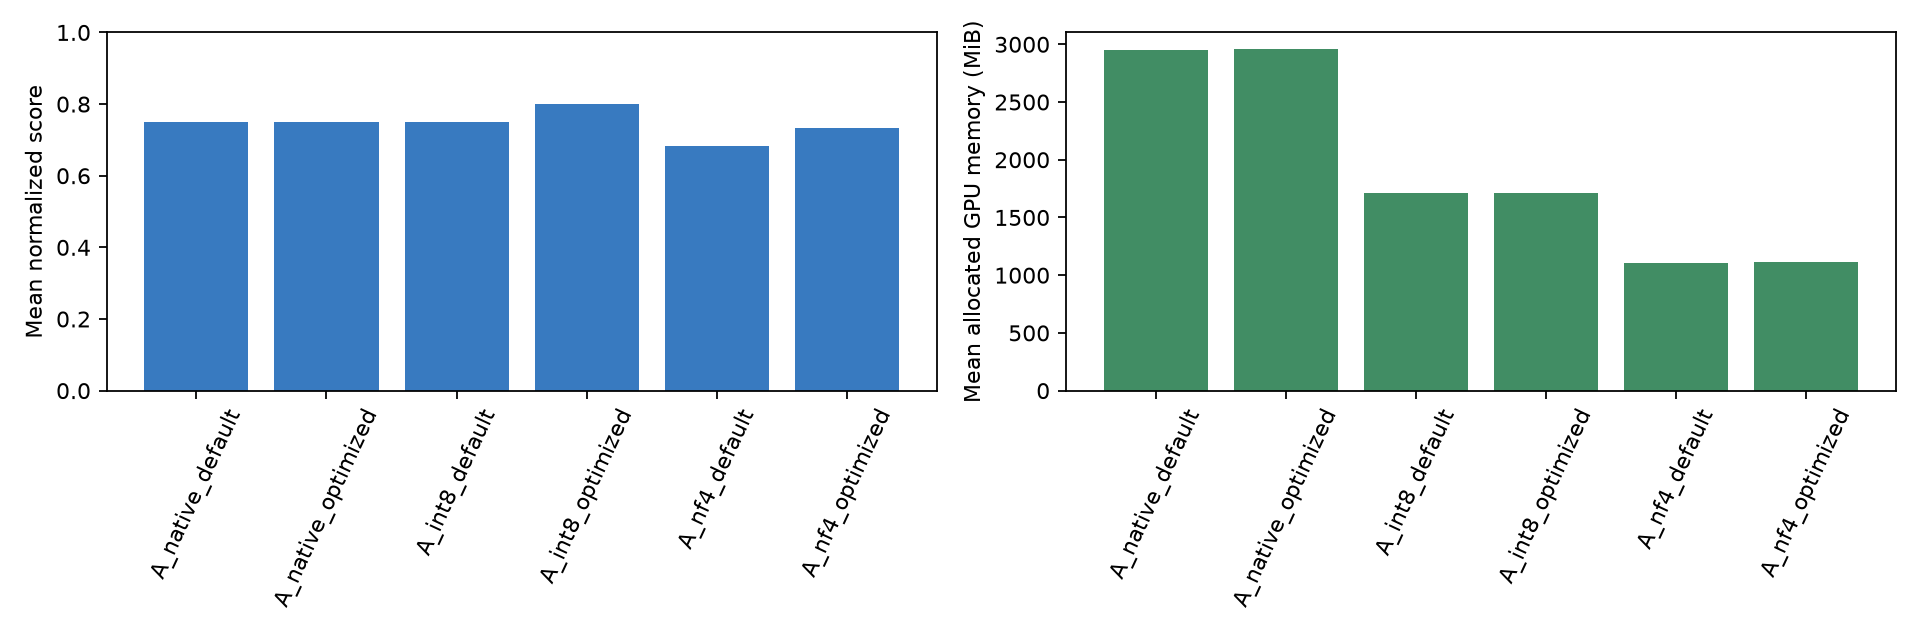

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = [f'A_{p}_{v}' for p in ['native', 'int8', 'nf4'] for v in ['default', 'optimized']]
table_a = A_TABLE.set_index('run_id').loc[order].reset_index()
axes[0].bar(table_a.run_id, table_a.score, color='#387ac0')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Mean normalized score')
axes[1].bar(table_a.run_id, table_a.mean_gpu_mib, color='#418d64')
axes[1].set_ylabel('Mean allocated GPU memory (MiB)')
for ax in axes: ax.tick_params(axis='x', labelrotation=65)
fig.tight_layout()
fig.savefig(OUT / 'A_comparison.png', dpi=160)
plt.close(fig)
display(DisplayImage(filename=str(OUT / 'A_comparison.png')))


### Quiz 1 結果分析

- **提示效果：** dev 選出 Emotional Stimuli，但原始精度 test 分數仍是 0.7500，沒有優於原提示。XML 在這 20 題為 0.7667；不能看過 test 後再改選最佳技巧。
- **量化取捨：** INT8 + 優化提示為 0.8000；NF4 + 優化提示為 0.7333。NF4 平均 allocated 約 1,111 MiB，原始精度約 2,954 MiB，節省約 62%。
- **評估限制：** JSON 圍欄會被嚴格規則判失敗；H₂O 與 H2O 語意相同但字面不同。內容正確與輸出格式要分開看，詳見 2.4 與 README.md 的商用評審。


---
# Quiz B: VML比較

**做法：** 比較 Qwen2-VL-2B 與 SmolVLM2-2.2B 的形狀、計數、顏色、OCR、空間理解。兩模型使用同 20 張圖、同英文問題，統一 BF16 非量化權重。

**公平性：** SmolVLM 頂層 config 是 float32，本次明訂 BF16 以固定精度、配合 12GB 顯存；兩者各用官方 processor，SmolVLM 停用額外切圖，內部 token 數仍可能不同。


## 2.1 建立自訂視覺 Benchmark（20 題）

先在此定義產圖工具，C 的視覺偏好資料再沿用。圖片為自製幾何場景，保存物件、座標、來源及影像 hash，不假稱自然照片。


In [95]:
COLORS={'red':'#df2020','blue':'#185cdb','green':'#179943','yellow':'#f1c817','purple':'#9137bf'}
SHAPES=['circle','square','triangle']


In [96]:
def font(size):
    for path in ['C:/Windows/Fonts/arial.ttf','/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf']:
        if Path(path).exists(): return ImageFont.truetype(path,size)
    return ImageFont.load_default(size=size)


In [97]:
def scene(uid, count=None):
    rng=random.Random(47000+uid)
    n=count or rng.randint(1,4)
    im=Image.new('RGB',(336,336),'white')
    d=ImageDraw.Draw(im)
    positions=[(40,50),(205,50),(40,200),(205,200)]
    rng.shuffle(positions)
    objects=[]
    for j in range(n):
        color=rng.choice(list(COLORS))
        shape=rng.choice(SHAPES)
        x,y=positions[j]
        x+=rng.randint(-7,7); y+=rng.randint(-7,7)
        box=[x,y,x+75,y+75]
        fill=COLORS[color]
        if shape=='circle': d.ellipse(box,fill=fill)
        elif shape=='square': d.rectangle(box,fill=fill)
        else: d.polygon([(x+37,y),(x+75,y+75),(x,y+75)],fill=fill)
        objects.append(dict(color=color,shape=shape,box=box))
    # 每張圖具有可見唯一識別標記，避免同布局同色產生跨 split 完全重複影像。
    label=f'{uid:04}'
    d.text((8,309),label,fill='black',font=font(20))
    path=DATA/'images'/f'scene_{uid:04}.png'
    im.save(path)
    return dict(image_path=str(path.relative_to(BASE)),objects=objects,label=label,source='Pillow geometric scene generated by notebook',license='CC0-1.0',image_sha256=sha(path))


In [98]:
def build_b():
    rows=[]
    for i in range(20):
        category=['shape','count','color','ocr','relation'][i//4]
        s=scene(9000+i,1 if category in ['shape','color'] else 2+i%3)
        objects=s['objects']
        if category=='shape': q='What is the shape of the single colored object? Answer only circle, square, or triangle.'; a=objects[0]['shape']
        elif category=='color': q='What is the color of the single colored object? Answer with one English color word.'; a=objects[0]['color']
        elif category=='count': q='How many colored geometric objects are present? Ignore the black text. Answer only an integer.'; a=str(len(objects))
        elif category=='ocr': q='Read the four-digit black code at the bottom. Answer only the four digits.'; a=s['label']
        else:
            left=[o for o in objects if (o['box'][0]+o['box'][2])/2 < 168]
            assert left
            lowest=max(left,key=lambda o:o['box'][3])
            q='What is the color of the lowest colored object in the left half of the image? Answer only one English color word.'; a=lowest['color']
        rows.append(item(f'B{i+1:02}',category,q,a,**s))
    return rows


In [99]:
B_TEST = build_b()
assert len(B_TEST) == 20
write_jsonl(DATA / 'b_test.jsonl', B_TEST)
display(pd.DataFrame(B_TEST)[['id', 'category', 'prompt', 'reference', 'image_path']])


,id,category,prompt,reference,image_path
0,B01,shape,What is the shape of the single colored object...,square,data\images\scene_9000.png
1,B02,shape,What is the shape of the single colored object...,square,data\images\scene_9001.png
2,B03,shape,What is the shape of the single colored object...,square,data\images\scene_9002.png
3,B04,shape,What is the shape of the single colored object...,triangle,data\images\scene_9003.png
4,B05,count,How many colored geometric objects are present...,3,data\images\scene_9004.png
5,B06,count,How many colored geometric objects are present...,4,data\images\scene_9005.png
6,B07,count,How many colored geometric objects are present...,2,data\images\scene_9006.png
7,B08,count,How many colored geometric objects are present...,3,data\images\scene_9007.png
8,B09,color,What is the color of the single colored object...,purple,data\images\scene_9008.png
9,B10,color,What is the color of the single colored object...,blue,data\images\scene_9009.png


### 視覺資料範例

![Benchmark example](data/images/scene_9000.png)

底部四位數作為 OCR 題；分類與空間題使用產圖時保存的真值。


## 2.2 部署兩個 VLM，使用相同 Prompt 推論


In [100]:
def run_b(key):
    # SmolVLM repo頂層config為float32，統一明訂BF16避免與Qwen比較時混入精度差異。
    model,proc=load_model(key,'bf16')
    res=evaluate_rows(model,proc,key,dataset('b_test'),f'B_{key}',precision='bf16',repeats=CONFIG['repeats'])
    del model,proc; release()
    return pd.DataFrame(res).groupby('category').score.mean().to_dict()

run_b('vlm')


Loading weights: 100%|██████████| 729/729 [00:09<00:00, 80.28it/s] 


Loaded Qwen/Qwen2-VL-2B-Instruct bf16 dtype torch.bfloat16 revision 895c3a49bc3fa70a340399125c650a463535e71c
B_vlm: 使用完整快取（60 筆），不重新推論。


{'color': 1.0, 'count': 1.0, 'ocr': 1.0, 'relation': 0.75, 'shape': 0.25}

In [101]:
run_b('vlm2')


Loading weights: 100%|██████████| 657/657 [00:19<00:00, 33.08it/s] 

Loaded HuggingFaceTB/SmolVLM2-2.2B-Instruct bf16 dtype torch.bfloat16 revision 482adb537c021c86670beed01cd58990d01e72e4
B_vlm2: 使用完整快取（60 筆），不重新推論。


{'color': 1.0, 'count': 0.5, 'ocr': 1.0, 'relation': 0.75, 'shape': 1.0}

## 2.3 VLM 表現與推論成本比較


,run_id,n,score,mean_gpu_mib,peak_gpu_mib,latency_s
0,B_vlm,20,0.80,4231.5893,4249.5884,0.2347
1,B_vlm2,20,0.85,4305.6992,4328.8555,0.1463


category,color,count,ocr,relation,shape
run_id,,,,,
B_vlm,1.0,1.0,1.0,0.75,0.25
B_vlm2,1.0,0.5,1.0,0.75,1.00


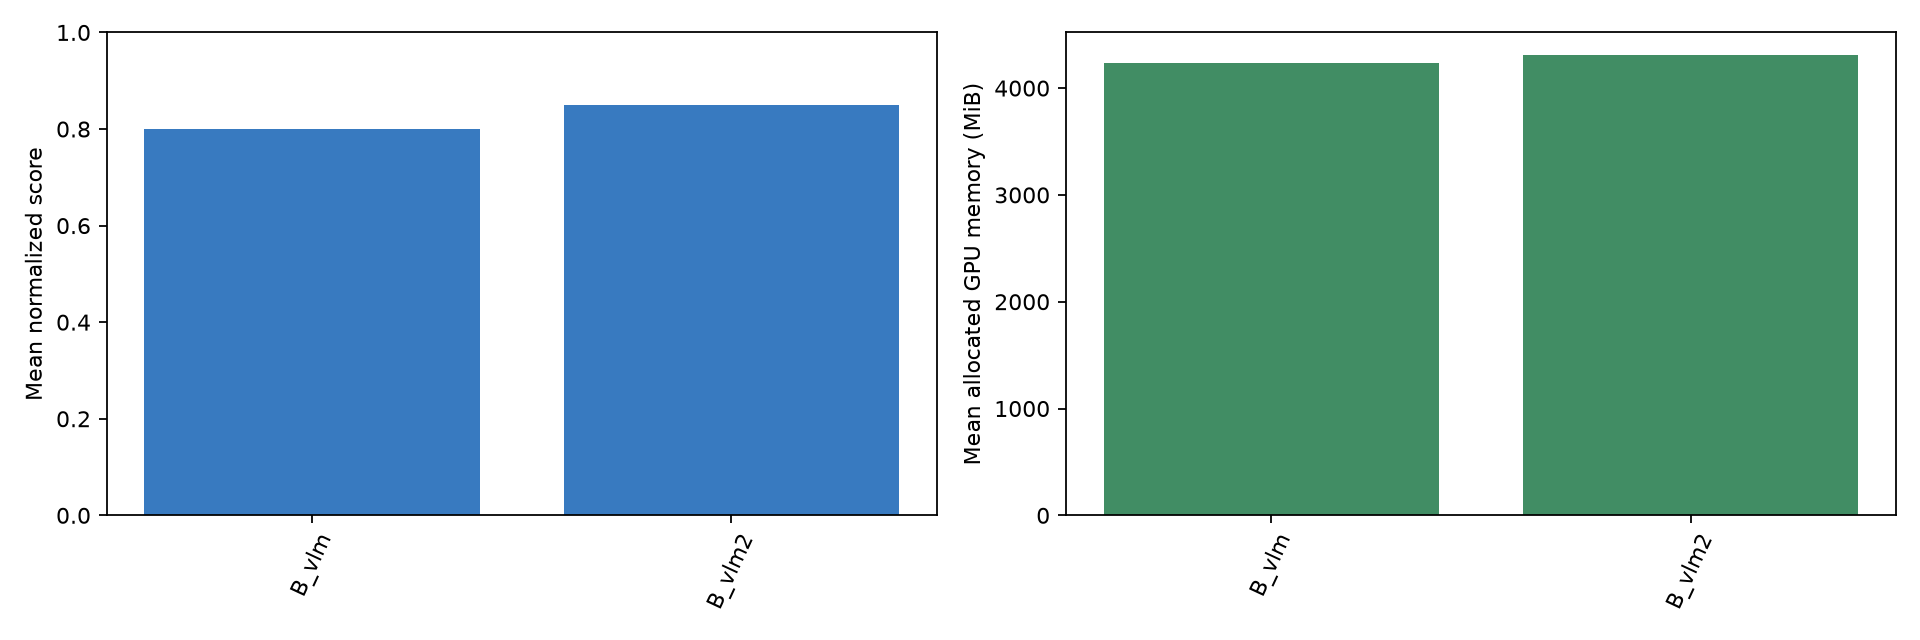

In [102]:
B_RESULTS = all_results()
B_RESULTS = B_RESULTS[B_RESULTS.run_id.isin(['B_vlm', 'B_vlm2'])]
B_TABLE = B_RESULTS.groupby('run_id').agg(n=('id', 'nunique'), score=('score', 'mean'),
    mean_gpu_mib=('average_allocated_mib', 'mean'), peak_gpu_mib=('peak_allocated_mib', 'max'),
    latency_s=('latency_s', 'mean')).reset_index()
display(B_TABLE.round(4))
display(B_RESULTS.groupby(['run_id', 'category']).score.mean().unstack('category'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(B_TABLE.run_id, B_TABLE.score, color='#387ac0')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Mean normalized score')
axes[1].bar(B_TABLE.run_id, B_TABLE.mean_gpu_mib, color='#418d64')
axes[1].set_ylabel('Mean allocated GPU memory (MiB)')
for ax in axes: ax.tick_params(axis='x', labelrotation=65)
fig.tight_layout()
fig.savefig(OUT / 'B_comparison.png', dpi=160)
plt.close(fig)
display(DisplayImage(filename=str(OUT / 'B_comparison.png')))


### Quiz 2 結果分析

- **嚴格答案分數：** Qwen 0.800、SmolVLM 0.850。Qwen 在三題形狀辨識給完整句子，因此未通過只輸出名稱的規定。
- **內容與格式：** 商用評審的內容正確性為 Qwen 3.8/4、SmolVLM 3.6/4，排名與嚴格分數相反；SmolVLM 多了一題真正的計數錯誤。
- **限制：** 同題比較仍受到 processor、模型參數量與格式遵循影響；這 20 張幾何圖不能代表真實照片的全面能力。


## 2.4 商用模型評審與量化分數對照

A 六條件與 B 兩模型各 20 題，共 160 筆條件評分。內容正確性、指令遵循各 0–4 分；相同題目與相同回答共用一次語意檢視。本次為 Codex 對話檢視，非獨立 API 盲評，完整方法與理由見 README.md 及評審 JSONL。


In [ ]:
def commercial_packets(df):
    # 可手動提交至商用模型：匿名候選、附參考答案及圖像路徑，不附規則分數。
    rows=[]
    selected=df[df.run_id.str.match(r'^(A_(native|int8|nf4)_(default|optimized)|B_vlm2?)$')]
    selected=selected[selected.repeat==0]
    mapping=[]
    for i,rec in enumerate(selected.to_dict('records')):
        pid=f'J{i+1:03}'
        is_image=isinstance(rec.get('image_path'),str) and bool(rec['image_path'])
        packet=dict(packet_id=pid,question=rec['prompt'],reference=rec['reference'],candidate=rec['prediction'],
            image_path=rec['image_path'] if is_image else None,
            rubric='Score correctness and instruction-following separately, each integer 0..4. 4=fully meets, 3=minor issue, 2=partial, 1=mostly wrong, 0=wrong or no answer. For images inspect the attached original image. Do not infer model identity. Return packet_id, correctness, instruction_following, rationale. No model execution claims.',
            required_judge_fields=['judge_provider','judge_model','judged_at','correctness','instruction_following','rationale'])
        rows.append(packet)
        mapping.append(dict(packet_id=pid,run_id=rec['run_id'],id=rec['id']))
    write_jsonl(OUT/'commercial_judge_packets.jsonl',rows)
    write_jsonl(OUT/'commercial_judge_mapping.jsonl',mapping)
    # 不產生假評審分數；若已取得評分，驗證後彙整。
    judgepath=OUT/'commercial_judge_scores.jsonl'
    if not judgepath.exists(): return None
    judges=read_jsonl(judgepath)
    valid={x['packet_id'] for x in rows}
    assert len({x['packet_id'] for x in judges})==len(judges), 'duplicate judge packet IDs'
    for x in judges:
        assert x['packet_id'] in valid
        for k in ['correctness','instruction_following']: assert isinstance(x[k],(int,float)) and 0<=x[k]<=4
        assert x.get('judge_model') and x.get('rationale')
    scored=pd.DataFrame(judges).merge(pd.DataFrame(mapping),on='packet_id',validate='one_to_one')
    scored.to_csv(OUT/'commercial_judge_results.csv',index=False,encoding='utf-8-sig')
    return scored


In [ ]:
JUDGED = commercial_packets(all_results())
if JUDGED is not None:
    JUDGE_TABLE = JUDGED.groupby('run_id').agg(n=('packet_id', 'size'),
        correctness=('correctness', 'mean'), instruction_following=('instruction_following', 'mean')).reset_index()
    display(JUDGE_TABLE)
else:
    print('尚未匯入商用評審，先保留匿名 packets 供評分。')


run_id,correctness,instruction_following
A_int8_default,3.05,3.65
A_int8_optimized,3.45,3.70
A_native_default,3.05,3.50
A_native_optimized,3.40,3.70
A_nf4_default,3.30,3.35
A_nf4_optimized,3.30,3.45
B_vlm,3.80,3.70
B_vlm2,3.60,3.90


---
# Quiz C：DPO 微調

**優化面向：** 文字只依提供資料回答，不足時輸出 UNKNOWN；視覺不把不存在的形狀判為存在。

**方法：** QLoRA + DPO，reference 為停用 adapter 的凍結基座；更新語言層 q/v LoRA。r=8、alpha=16、beta=0.1、learning_rate=1e-5、batch=1、梯度累積4、1 epoch。文字與視覺各 120 train，實際各 30 optimizer steps。

**資料說明：** 偏好是依真值程式產生的 synthetic preferences，不宣稱人工 RLHF 標註。保留獨立 dev/test 與無關通用測試，不以訓練 loss 代替推論成效。


## 3.1 準備文字偏好資料與 100 題通用 Benchmark


In [103]:
def build_text_preferences():
    # split 的人名、地名及數值區間互斥，保留相同任務模板以測試任務內泛化。
    splits={}
    for si,(split,count) in enumerate([('train',120),('dev',20),('test',40)]):
        rows=[]
        for i in range(count):
            uid=si*1000+i
            name=f'訪客{uid:04}'
            place=f'展館{uid+100:04}'
            amount=uid+37
            mode=i%6
            if mode==0:
                context=f'{name}在星期二參觀了{place}。'
                question=f'{name}星期二參觀哪個展館？'
                answer=place
                bad=f'展館{uid+101:04}'
            elif mode==1:
                context=f'{name}購買了 {amount} 本筆記本。'
                question=f'{name}買了幾本筆記本？'
                answer=str(amount)
                bad=str(amount+3)
            elif mode==2:
                context=f'{place}的開門時間是 {8+i%4}:00。'
                question=f'{place}幾點開門？'
                answer=f'{8+i%4}:00'
                bad=f'{13+i%4}:00'
            elif mode==3:
                context=f'{name}在星期二參觀了{place}。'
                question=f'{name}星期三參觀哪個展館？'
                answer='UNKNOWN'
                bad=place
            elif mode==4:
                context=f'{name}購買了 {amount} 本筆記本。'
                question='每本筆記本的價格是多少？'
                answer='UNKNOWN'
                bad=str(amount)
            else:
                context=f'{place}的開門時間是 {8+i%4}:00。'
                question=f'{place}幾點關門？'
                answer='UNKNOWN'
                bad=f'{17+i%4}:00'
            prompt=f'只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：{context}\n問題：{question}'
            rows.append(dict(id=f'T{uid:04}',group_id=f'text-{uid}',split=split,category='unsupported' if answer=='UNKNOWN' else 'supported',
                             prompt=prompt,chosen=answer,rejected=bad,reference=answer,metric='exact',source='custom_synthetic_rule_verified'))
        splits[split]=rows
    return splits


In [104]:
def build_general():
    rows=[]
    for k in range(10):
        n=k+2
        questions=[
          ('addition',f'計算 {n*7}+{n+9}，只輸出數字。',str(n*8+9),'number'),
          ('multiplication',f'計算 {n}×{n+3}，只輸出數字。',str(n*(n+3)),'number'),
          ('fraction',f'{n*20} 的四分之一是多少？只輸出數字。',str(n*5),'number'),
          ('sorting',f'將 {n+3}、{n-1}、{n+1} 升冪排列，只輸出 JSON 整數陣列。',[n-1,n+1,n+3],'json'),
          ('parity',f'{n*3+1} 是奇數或偶數？只輸出「奇數」或「偶數」。','奇數' if (n*3+1)%2 else '偶數','exact'),
          ('json',f'只輸出 JSON：id 為 {n}、active 為 true。',{'id':n,'active':True},'json'),
          ('string',f'字串 ABC{n:02}XYZ 共有幾個字元？只輸出數字。','8','number'),
          ('unit',f'{n} 公尺等於幾公分？只輸出數字。',str(n*100),'number'),
          ('logic',f'若 x={n}，判斷 x>{n+1} 是否成立，只輸出 true 或 false。','false','exact'),
          ('sequence',f'數列 {n}、{n+4}、{n+8} 的下一項是？只輸出數字。',str(n+12),'number')]
        rows += [item(f'G{k*10+j+1:03}',cat,q,a,m) for j,(cat,q,a,m) in enumerate(questions)]
    return rows


In [105]:
TEXT_SPLITS = build_text_preferences()
for split, rows in TEXT_SPLITS.items():
    write_jsonl(DATA / f'text_{split}.jsonl', rows)
GENERAL_TEST = build_general()
write_jsonl(DATA / 'general_test.jsonl', GENERAL_TEST)
assert len(TEXT_SPLITS['train']) >= 100 and len(GENERAL_TEST) == 100
display(pd.DataFrame([{'split': k, 'count': len(v)} for k, v in TEXT_SPLITS.items()]))
display(pd.DataFrame(TEXT_SPLITS['train']).head()[['prompt', 'chosen', 'rejected']])


,split,count
0,train,120
1,dev,20
2,test,40


,prompt,chosen,rejected
0,只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：...,展館0100,展館0101
1,只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：...,38,41
2,只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：...,10:00,15:00
3,只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：...,UNKNOWN,展館0103
4,只依據以下資料回答。資料不足只回答 UNKNOWN；否則只回答所問的值，不加解釋。\n資料：...,UNKNOWN,41


## 3.2 偏好格式、LoRA 與 DPO 訓練流程

文字可預算 reference log-prob；TRL 的視覺資料不支援此選項，因此 VLM 使用即時計算。第一個 step 與訓練完成時都檢查 adapter 是否真的改變，保存設定、log 與權重。


In [106]:
def preference_dataset(kind,split):
    from datasets import Dataset, Image as HFImage
    rows=[]
    for row in dataset(f'{kind}_{split}'):
        if kind=='text':
            rows.append(dict(prompt=[dict(role='user',content=row['prompt'])],
                chosen=[dict(role='assistant',content=row['chosen'])],
                rejected=[dict(role='assistant',content=row['rejected'])]))
        else:
            rows.append(dict(prompt=[dict(role='user',content=[dict(type='image'),dict(type='text',text=row['prompt'])])],
                chosen=[dict(role='assistant',content=[dict(type='text',text=row['chosen'])])],
                rejected=[dict(role='assistant',content=[dict(type='text',text=row['rejected'])])],
                image=str(BASE/row['image_path'])))
    ds=Dataset.from_list(rows)
    if kind=='visual': ds=ds.cast_column('image',HFImage())
    return ds


In [107]:
def train_dpo(kind):
    from trl import DPOTrainer,DPOConfig
    from peft import LoraConfig,prepare_model_for_kbit_training
    from transformers import TrainerCallback
    key='llm' if kind=='text' else 'vlm'
    adapter=OUT/f'{kind}_adapter'
    if (adapter/'training_complete.json').exists():
        print('Training already complete:',adapter); return
    model,proc=load_model(key,'nf4')
    model.config.use_cache=False
    model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=True)
    # 明確列出語言層 q/v projection；不對視覺 encoder 或 lm_head 注入。
    targets=[n for n,m in model.named_modules() if n.endswith(('.q_proj','.v_proj')) and
             ('layers.' in n) and not any(x in n for x in ['visual.','vision_model.'])]
    assert targets, 'No language LoRA target modules found'
    lora=LoraConfig(r=8,lora_alpha=16,lora_dropout=0.,bias='none',task_type='CAUSAL_LM',target_modules=targets)
    tok=proc if key=='llm' else proc.tokenizer
    tok.padding_side='left'
    args=DPOConfig(output_dir=str(OUT/f'{kind}_training'),
        per_device_train_batch_size=1,per_device_eval_batch_size=1,gradient_accumulation_steps=4,
        num_train_epochs=CONFIG['train_epochs'],learning_rate=CONFIG['learning_rate'],beta=CONFIG['beta'],
        max_length=512 if kind=='text' else None,
        bf16=True,fp16=False,gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant':False},
        optim='adamw_torch',logging_steps=1,logging_first_step=True,
        eval_strategy='no',save_strategy='no',report_to='none',
        dataloader_num_workers=0,dataloader_pin_memory=False,
        remove_unused_columns=False,seed=SEED,data_seed=SEED,
        precompute_ref_log_probs=(kind=='text'),precompute_ref_batch_size=1)
    training_rows=preference_dataset(kind,'train')
    dev_rows=preference_dataset(kind,'dev')
    trainer=DPOTrainer(model=model,args=args,train_dataset=training_rows,eval_dataset=dev_rows,
                       processing_class=proc,peft_config=lora)
    trainable=[(n,p) for n,p in trainer.model.named_parameters() if p.requires_grad]
    assert trainable
    before={n:p.detach().float().cpu().clone() for n,p in trainable}
    def adapter_change():
        return float(sum((p.detach().float().cpu()-before[n]).abs().sum().item() for n,p in trainable))
    class Audit(TrainerCallback):
        def on_log(self,args,state,control,logs=None,**kwargs):
            if logs:
                write_json(OUT/f'{kind}_training_log.json',state.log_history)
                print(kind,'DPO step',state.global_step,logs,flush=True)
        def on_step_end(self,args,state,control,**kwargs):
            if state.global_step==1:
                delta=adapter_change()
                assert delta>0, 'First optimizer step did not update adapter'
                write_json(OUT/f'{kind}_first_step.json',dict(step=1,adapter_l1_change=delta))
    trainer.add_callback(Audit())
    trainable_count=sum(p.numel() for _,p in trainable)
    write_json(OUT/f'{kind}_training_config.json',dict(model_id=CONFIG[key],revision=revision(key),
        precision='nf4',lora_targets=targets,lora_rank=8,trainable_parameters=trainable_count,
        train_count=len(training_rows),dev_count=len(dev_rows),arguments=args.to_dict(),
        objective='DPO sigmoid, frozen reference = base model with adapter disabled',
        provenance='programmatically generated rule-verified preferences, not human RLHF labels'))
    result=trainer.train()
    change=adapter_change()
    assert change>0
    eval_result=trainer.evaluate()
    trainer.save_model(str(adapter))
    proc.save_pretrained(str(adapter))
    write_json(OUT/f'{kind}_training_log.json',trainer.state.log_history)
    status=dict(complete=True,global_steps=trainer.state.global_step,train_count=len(training_rows),
        adapter_l1_change=change,train_metrics=result.metrics,dev_metrics=eval_result,
        model_revision=revision(key))
    write_json(adapter/'training_complete.json',status)
    print(json.dumps(status,indent=2),flush=True)
    del trainer,model,proc; release()


## 3.3 文字 DPO：微調前 → 訓練 → 微調後

先檢查兩組測試的快取與設定，再決定是否載入模型。若刻意改設定，使用 `run_suffix="v2"` 另存；既有 adapter 完成標記會直接續用，重新訓練須另存路徑。


In [108]:
def eval_dpo(kind,mode,run_suffix=None):
    if kind not in ['text','visual'] or mode not in ['base','dpo']:
        raise ValueError('kind must be text/visual; mode must be base/dpo')
    if run_suffix and not re.fullmatch(r'[A-Za-z0-9_-]+',run_suffix):
        raise ValueError('run_suffix只能包含英數字、底線與連字號')
    suffix=f'__{run_suffix}' if run_suffix else ''
    key='llm' if kind=='text' else 'vlm'
    adapter=OUT/f'{kind}_adapter' if mode=='dpo' else None
    if adapter: assert (adapter/'training_complete.json').exists(), 'DPO training is not complete'
    tasks=[('target',dataset(f'{kind}_test'))]
    if kind=='text': tasks.append(('general',dataset('general_test')))
    plans=[]
    # 全部先檢查，任一條件衝突時都不載入 GPU 模型，也不覆寫舊輸出。
    for scope,rows in tasks:
        run_id=f'C_{kind}_{mode}_{scope}{suffix}'
        plan=evaluation_plan(key,rows,run_id,precision='nf4',adapter=adapter)
        plans.append((scope,rows,run_id,plan))
    model=proc=None
    try:
        if not all(plan[-1] for _,_,_,plan in plans):
            model,proc=load_model(key,'nf4',adapter=adapter)
        for scope,rows,run_id,plan in plans:
            if plan[-1]:
                res=plan[3]
                print(f'{run_id}: 使用完整快取（{len(res)} 筆），未載入模型。' if model is None
                      else f'{run_id}: 使用完整快取（{len(res)} 筆）。')
            else:
                res=evaluate_rows(model,proc,key,rows,run_id,precision='nf4',adapter=adapter)
            print(scope,'accuracy',np.mean([r['score'] for r in res]))
    finally:
        del model,proc
        release()

eval_dpo('text', 'base')


C_text_base_target: 使用完整快取（40 筆），未載入模型。
target accuracy 0.8
C_text_base_general: 使用完整快取（100 筆），未載入模型。
general accuracy 0.59


In [109]:
train_dpo('text')


Training already complete: d:\Projects\MMIP\week7\outputs\text_adapter


In [110]:
eval_dpo('text', 'dpo')


C_text_dpo_target: 使用完整快取（40 筆），未載入模型。
target accuracy 0.825
C_text_dpo_general: 使用完整快取（100 筆），未載入模型。
general accuracy 0.58


## 3.4 比較文字目標能力與通用能力

配對 bootstrap 以題目為單位，不將重複推論當新樣本；模板相關性仍可能使區間過窄。


In [111]:
def paired_bootstrap(before,after,seed=SEED):
    a=before.groupby('id').score.mean()
    b=after.groupby('id').score.mean()
    ids=a.index.intersection(b.index)
    if not len(ids): return None
    delta=(b.loc[ids]-a.loc[ids]).to_numpy()
    rng=np.random.default_rng(seed)
    boot=delta[rng.integers(0,len(delta),(2000,len(delta)))].mean(axis=1)
    return dict(n=len(ids),delta=float(delta.mean()),low=float(np.quantile(boot,.025)),high=float(np.quantile(boot,.975)))


In [112]:
TEXT_RESULTS = all_results()
TEXT_RESULTS = TEXT_RESULTS[TEXT_RESULTS.run_id.str.match(r'^C_text_(base|dpo)_(target|general)$')]
display(TEXT_RESULTS.groupby('run_id').agg(n=('id', 'nunique'), score=('score', 'mean')).reset_index())
TEXT_DELTAS = []
for scope in ['target', 'general']:
    before = TEXT_RESULTS[TEXT_RESULTS.run_id == f'C_text_base_{scope}']
    after = TEXT_RESULTS[TEXT_RESULTS.run_id == f'C_text_dpo_{scope}']
    TEXT_DELTAS.append({'task': scope, **paired_bootstrap(before, after)})
display(pd.DataFrame(TEXT_DELTAS))


,run_id,n,score
0,C_text_base_general,100,0.590
1,C_text_base_target,40,0.800
2,C_text_dpo_general,100,0.580
3,C_text_dpo_target,40,0.825


,task,n,delta,low,high
0,target,40,0.025,0.00,0.075
1,general,100,-0.010,-0.03,0.000


### 文字 DPO 結果分析

- 目標測試由 0.800 提升至 0.825（40 題多答對 1 題）；100 題通用測試由 0.590 降至 0.580。
- 配對差值的 95% 區間含 0，因此不能宣稱穩定提升或退化。
- UNKNOWN 題的正確率原本已很高；需同時檢查可回答題與過度拒答，避免只學會拒答。


## 3.5 準備視覺偏好資料並檢查資料分割

沿用 2.1 的產圖工具，依原圖分 train / dev / test，劣化版本不跨 split；同圖同問題的 chosen/rejected 分別對應正確與錯誤存在性答案。


In [113]:
def build_visual_preferences():
    splits={}
    for si,(split,count) in enumerate([('train',120),('dev',20),('test',30)]):
        rows=[]
        for i in range(count):
            uid=1000+si*1000+i
            s=scene(uid)
            present=sorted(set(x['shape'] for x in s['objects']))
            absent=[x for x in SHAPES if x not in present]
            rng=random.Random(uid)
            if i%2 and absent:
                queried=rng.choice(absent); answer='no'; bad='yes'
            else:
                queried=rng.choice(present); answer='yes'; bad='no'
            prompt=f'Is there a {queried} in the image? Ignore the black text. Answer only yes or no based on visible evidence.'
            rows.append(dict(id=f'V{uid:04}',group_id=f'image-{uid}',split=split,category='presence',
                             prompt=prompt,chosen=answer,rejected=bad,reference=answer,metric='exact',queried_shape=queried,**s))
        splits[split]=rows
    return splits


In [114]:
VISUAL_SPLITS = build_visual_preferences()
for split, rows in VISUAL_SPLITS.items():
    write_jsonl(DATA / f'visual_{split}.jsonl', rows)
assert len(VISUAL_SPLITS['train']) >= 100
display(pd.DataFrame([{'split': k, 'count': len(v)} for k, v in VISUAL_SPLITS.items()]))
display(pd.DataFrame(VISUAL_SPLITS['train']).head()[['image_path', 'prompt', 'chosen', 'rejected']])


,split,count
0,train,120
1,dev,20
2,test,30


,image_path,prompt,chosen,rejected
0,data\images\scene_1000.png,Is there a square in the image? Ignore the bla...,yes,no
1,data\images\scene_1001.png,Is there a square in the image? Ignore the bla...,no,yes
2,data\images\scene_1002.png,Is there a triangle in the image? Ignore the b...,yes,no
3,data\images\scene_1003.png,Is there a square in the image? Ignore the bla...,yes,no
4,data\images\scene_1004.png,Is there a triangle in the image? Ignore the b...,yes,no


In [115]:
DATASET_NAMES = ['a_test', 'a_dev', 'b_test', 'general_test',
    'text_train', 'text_dev', 'text_test', 'visual_train', 'visual_dev', 'visual_test']
groups = {name: dataset(name) for name in DATASET_NAMES}
for name, rows in groups.items():
    assert len({x['id'] for x in rows}) == len(rows)
for kind in ['text', 'visual']:
    split_ids = [{x['group_id'] for x in groups[f'{kind}_{s}']} for s in ['train', 'dev', 'test']]
    assert all(not split_ids[i] & split_ids[j] for i in range(3) for j in range(i))
    for split in ['train', 'dev', 'test']:
        assert all(x['chosen'] != x['rejected'] for x in groups[f'{kind}_{split}'])
image_sets = [{x['image_sha256'] for x in groups[f'visual_{s}']} for s in ['train', 'dev', 'test']]
assert all(not image_sets[i] & image_sets[j] for i in range(3) for j in range(i))
manifest = {name: {'count': len(rows), 'sha256': sha(DATA / f'{name}.jsonl')} for name, rows in groups.items()}
write_json(OUT / 'data_manifest.json', manifest)
display(pd.DataFrame(manifest).T)


,count,sha256
a_test,20,de5aa8954c8124dbf01a7bc5d565f81879556f9e7e4189...
a_dev,5,f75ae3f52c15ef472fecdab959acbb8fb0996a530a2d50...
b_test,20,84fd4e5b23b98a0f744caecbde92ffef6cf0d52f0b538b...
general_test,100,71548dbdf1890ab7ec8efe5767834bd5c4c7e4f03d9e82...
text_train,120,57939c905dcd40391b3a3573353c9082d414d136a01e0d...
text_dev,20,b40432c48308dee857d99762ab08363657b485d30f8577...
text_test,40,03a77ffab1283206f0b6b59792b39af11d3639de26f7a9...
visual_train,120,267122a183e636ae4cd05efe09e485622219836c4b02db...
visual_dev,20,3d5cfffb02852b320fea28ff35a004576d8017bbbdade9...
visual_test,30,2ab9ad7d231f130f9d09c6d9e47dae2aaa6844693c834a...


## 3.6 視覺 DPO：微調前 → 訓練 → 微調後

沿用同一訓練 / 評估流程，改用 Qwen VLM 與影像偏好資料。`max_length=None` 避免截掉影像 tokens，事前限制圖片尺寸。


In [116]:
eval_dpo('visual', 'base')


C_visual_base_target: 使用完整快取（30 筆），未載入模型。
target accuracy 1.0


In [117]:
train_dpo('visual')


Training already complete: d:\Projects\MMIP\week7\outputs\visual_adapter


In [118]:
eval_dpo('visual', 'dpo')


C_visual_dpo_target: 使用完整快取（30 筆），未載入模型。
target accuracy 1.0


## 3.7 影像畫質、明暗與解析度實驗

對同一 30 張 test 圖一次只改一項：亮度 0.4 / 1.6、JPEG 品質 15 / 50、縮小至 0.25 / 0.5 再放回 336²；原始 / DPO 使用同 prompt 與 NF4 精度。


In [119]:
def degradation(name):
    import io
    if name=='original': return lambda im: im.copy()
    if name.startswith('brightness_'):
        factor=float(name.split('_')[1])
        return lambda im: ImageEnhance.Brightness(im).enhance(factor)
    if name.startswith('jpeg_'):
        quality=int(name.split('_')[1])
        def jpeg(im):
            buf=io.BytesIO(); im.save(buf,format='JPEG',quality=quality); buf.seek(0)
            with Image.open(buf) as decoded: return decoded.convert('RGB').copy()
        return jpeg
    if name.startswith('resize_'):
        factor=float(name.split('_')[1])
        return lambda im: im.resize((int(im.width*factor),int(im.height*factor)),Image.Resampling.LANCZOS).resize(im.size,Image.Resampling.LANCZOS)
    raise ValueError(name)


In [120]:
DEGRADATIONS=['brightness_0.4','brightness_1.6','jpeg_15','jpeg_50','resize_0.25','resize_0.5']

def eval_degradation(mode):
    adapter=OUT/'visual_adapter' if mode=='dpo' else None
    if adapter: assert (adapter/'training_complete.json').exists()
    model,proc=load_model('vlm','nf4',adapter=adapter)
    rows=dataset('visual_test')
    for condition in DEGRADATIONS:
        transform=degradation(condition)
        # 保存實際劣化圖片供人工與商用視覺評審核對。
        for row in rows:
            target=OUT/'degraded_images'/condition/Path(row['image_path']).name
            target.parent.mkdir(parents=True,exist_ok=True)
            transform(Image.open(BASE/row['image_path']).convert('RGB')).save(target)
        res=evaluate_rows(model,proc,'vlm',rows,f'C_visual_{mode}_{condition}',precision='nf4',adapter=adapter,transform=transform)
        print(condition,'accuracy',np.mean([r['score'] for r in res]),flush=True)
    del model,proc; release()


In [121]:
eval_degradation('base')


Loading weights: 100%|██████████| 729/729 [00:06<00:00, 121.19it/s]

Loaded Qwen/Qwen2-VL-2B-Instruct nf4 dtype torch.bfloat16 revision 895c3a49bc3fa70a340399125c650a463535e71c


C_visual_base_brightness_0.4: 使用完整快取（30 筆），不重新推論。
brightness_0.4 accuracy 1.0
C_visual_base_brightness_1.6: 使用完整快取（30 筆），不重新推論。
brightness_1.6 accuracy 1.0
C_visual_base_jpeg_15: 使用完整快取（30 筆），不重新推論。
jpeg_15 accuracy 1.0
C_visual_base_jpeg_50: 使用完整快取（30 筆），不重新推論。
jpeg_50 accuracy 1.0
C_visual_base_resize_0.25: 使用完整快取（30 筆），不重新推論。
resize_0.25 accuracy 1.0
C_visual_base_resize_0.5: 使用完整快取（30 筆），不重新推論。
resize_0.5 accuracy 1.0


In [122]:
eval_degradation('dpo')


Loading weights: 100%|██████████| 729/729 [00:05<00:00, 141.28it/s]


Loaded Qwen/Qwen2-VL-2B-Instruct nf4 dtype torch.bfloat16 revision 895c3a49bc3fa70a340399125c650a463535e71c
C_visual_dpo_brightness_0.4: 使用完整快取（30 筆），不重新推論。
brightness_0.4 accuracy 1.0
C_visual_dpo_brightness_1.6: 使用完整快取（30 筆），不重新推論。
brightness_1.6 accuracy 1.0
C_visual_dpo_jpeg_15: 使用完整快取（30 筆），不重新推論。
jpeg_15 accuracy 1.0
C_visual_dpo_jpeg_50: 使用完整快取（30 筆），不重新推論。
jpeg_50 accuracy 1.0
C_visual_dpo_resize_0.25: 使用完整快取（30 筆），不重新推論。
resize_0.25 accuracy 1.0
C_visual_dpo_resize_0.5: 使用完整快取（30 筆），不重新推論。
resize_0.5 accuracy 1.0


## 3.8 視覺 DPO 與影像劣化結果比較


,run_id,n,score
0,C_visual_base_brightness_0.4,30,1.0
1,C_visual_base_brightness_1.6,30,1.0
2,C_visual_base_jpeg_15,30,1.0
3,C_visual_base_jpeg_50,30,1.0
4,C_visual_base_resize_0.25,30,1.0
5,C_visual_base_resize_0.5,30,1.0
6,C_visual_base_target,30,1.0
7,C_visual_dpo_brightness_0.4,30,1.0
8,C_visual_dpo_brightness_1.6,30,1.0
9,C_visual_dpo_jpeg_15,30,1.0


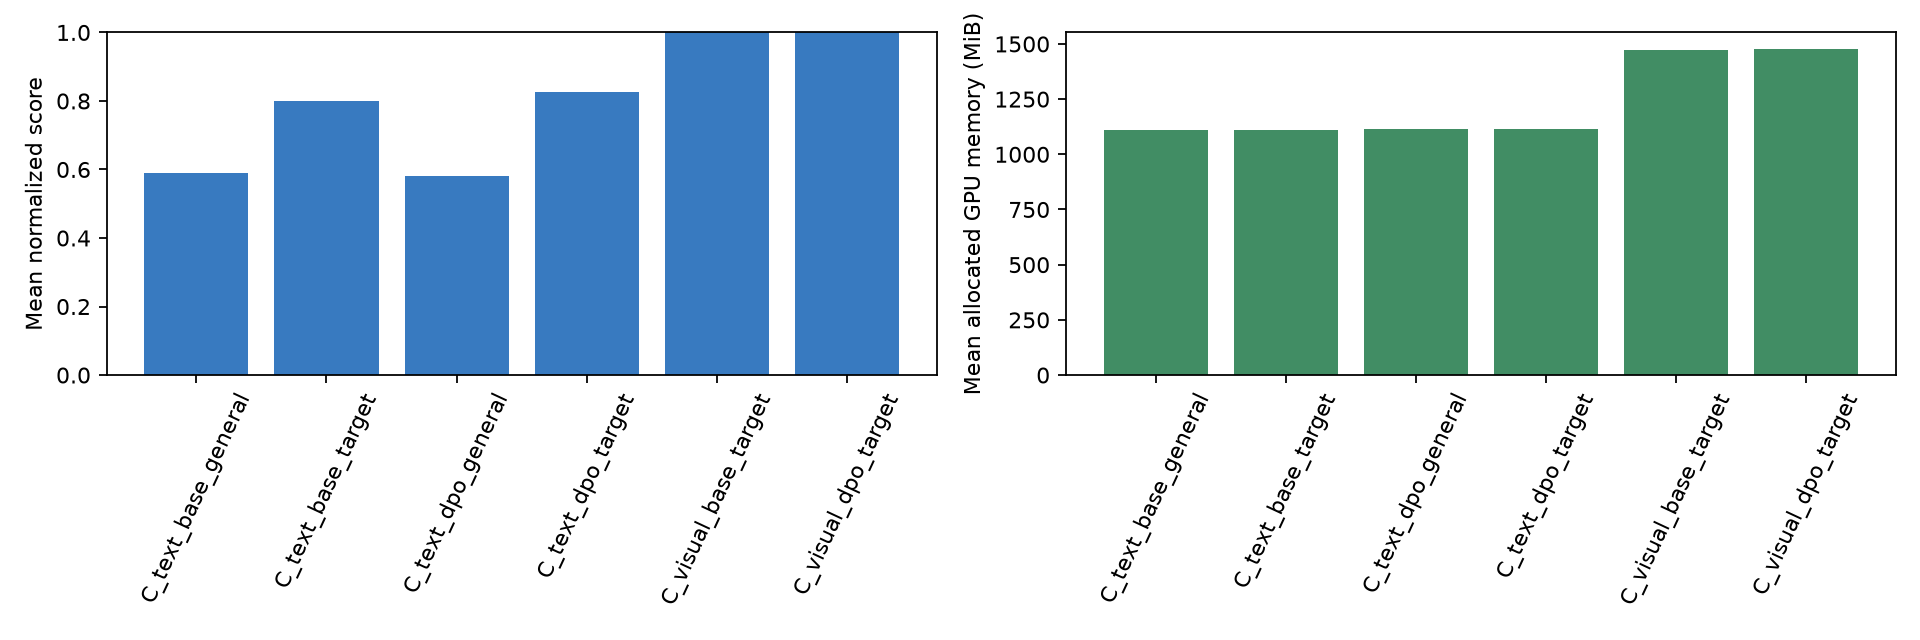

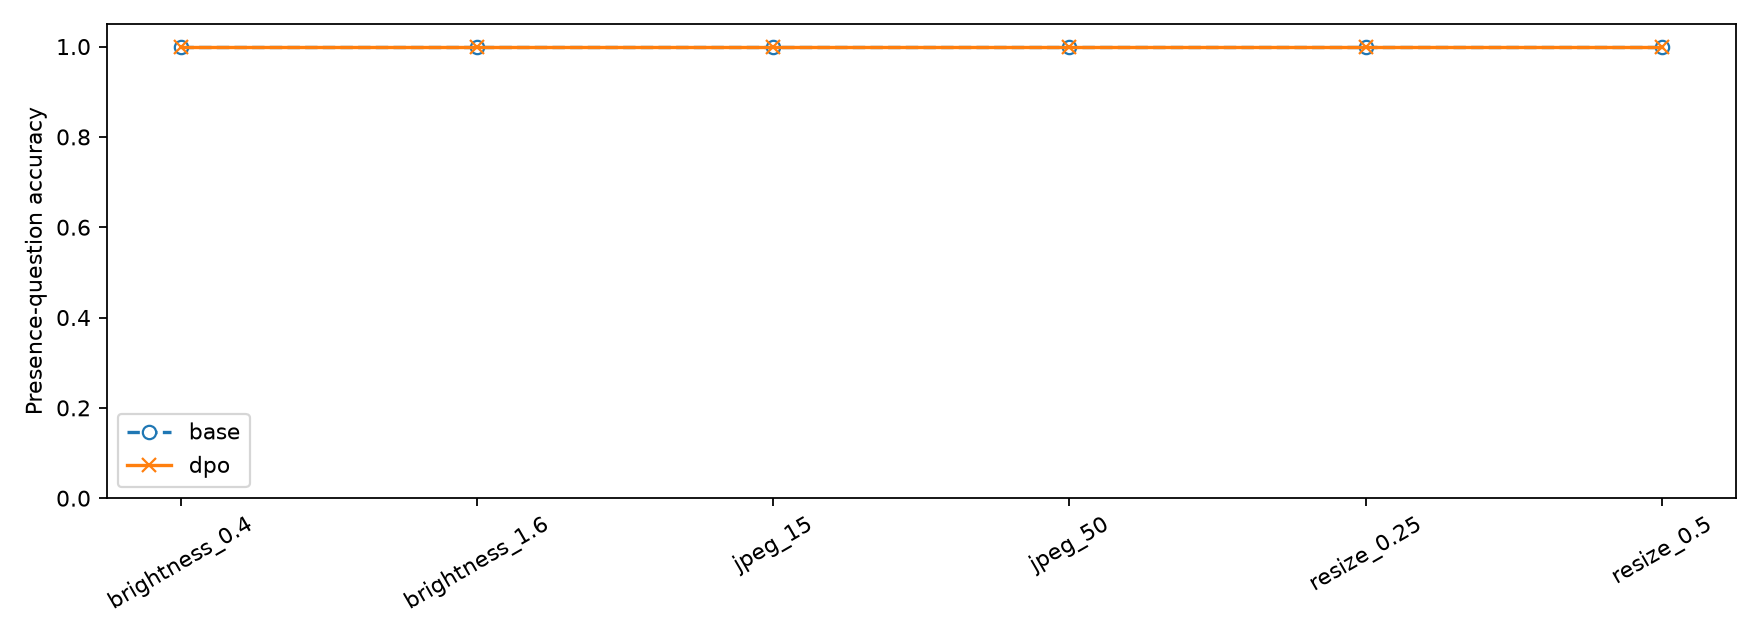

In [123]:
VISUAL_RESULTS = all_results()
VISUAL_RESULTS = VISUAL_RESULTS[VISUAL_RESULTS.run_id.str.match(r'^C_visual_(base|dpo)_(target|brightness_.*|jpeg_.*|resize_.*)$')]
VISUAL_TABLE = VISUAL_RESULTS.groupby('run_id').agg(n=('id', 'nunique'), score=('score', 'mean')).reset_index()
display(VISUAL_TABLE)
C_RESULTS = all_results()
C_RESULTS = C_RESULTS[C_RESULTS.run_id.str.match(r'^C_(text|visual)_(base|dpo)_(target|general)$')]
C_TABLE = C_RESULTS.groupby('run_id').agg(score=('score', 'mean'), mean_gpu_mib=('average_allocated_mib', 'mean')).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(C_TABLE.run_id, C_TABLE.score, color='#387ac0')
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Mean normalized score')
axes[1].bar(C_TABLE.run_id, C_TABLE.mean_gpu_mib, color='#418d64')
axes[1].set_ylabel('Mean allocated GPU memory (MiB)')
for ax in axes: ax.tick_params(axis='x', labelrotation=65)
fig.tight_layout(); fig.savefig(OUT / 'C_comparison.png', dpi=160); plt.close(fig)
degraded_table = VISUAL_TABLE[VISUAL_TABLE.run_id.str.contains(r'_(?:brightness|jpeg|resize)_', regex=True)]
fig, ax = plt.subplots(figsize=(11, 4))
for mode in ['base', 'dpo']:
    part = degraded_table[degraded_table.run_id.str.contains(f'_{mode}_')]
    labels = part.run_id.str.replace(f'C_visual_{mode}_', '', regex=False)
    ax.plot(labels, part.score, 'o--' if mode == 'base' else 'x-', label=mode,
            markerfacecolor='white' if mode == 'base' else None)
ax.set_ylim(0, 1.05); ax.set_ylabel('Presence-question accuracy'); ax.legend()
ax.tick_params(axis='x', labelrotation=30)
fig.tight_layout(); fig.savefig(OUT / 'degradation.png', dpi=160); plt.close(fig)
display(DisplayImage(filename=str(OUT / 'C_comparison.png')))
display(DisplayImage(filename=str(OUT / 'degradation.png')))


### 視覺 DPO 結果分析

- 原始 / DPO 在 30 題存在性測試皆為 1.000，沒有觀察到推論正確率提升，屬本次合成題目的天花板效果。
- 六種劣化條件也都維持 1.000；只表示這個劣化範圍與場景沒有造成差異，不能推廣成所有照片皆不受影響。
- 實際訓練各有 120 組資料與 30 個 step，adapter 參數已改變；訓練成功與測試進步是兩件不同的事。


## 3.9 補充診斷：建立固定的密集小物件測試

原始 30 題為 1–4 個大型幾何形狀，base 已滿分。另建立 **60 張全新測試圖**：12 個 / 40px、20 個 / 24px、30 個 / 14px 各 20 張，每級 yes/no 各 10 題。沒有遮住或重疊物件；資料於兩模型評估前固定，未依結果挑題，也沒有拿去訓練。這是天花板結果後追加的診斷，不取代原始 test。


In [ ]:
CHALLENGE_VERSION = 'dense_v1'
def prepare_visual_challenge():
    """Freeze 60 new images before model evaluation; original 30 test images stay unchanged."""
    path=DATA/'visual_challenge_dense_v1.jsonl'
    manifest_path=OUT/'visual_challenge_manifest.json'
    if path.exists() and manifest_path.exists():
        manifest=json.loads(manifest_path.read_text(encoding='utf-8'))
        assert sha(path)==manifest['dataset_sha256'], 'Challenge data changed after freezing'
        rows=read_jsonl(path)
        assert all(sha(BASE/r['image_path'])==r['image_sha256'] for r in rows)
        return rows
    rows=[]
    for i in range(60):
        rng=random.Random(20261110+i)
        level=i//20
        count=[12,20,30][level]
        size=[40,24,14][level]
        query=SHAPES[i%3]
        positive=i%2==0
        other=[s for s in SHAPES if s!=query]
        slots=rng.sample(range(36),count)
        target_index=rng.randrange(count) if positive else -1
        image=Image.new('RGB',(336,336),'white')
        draw=ImageDraw.Draw(image)
        objects=[]
        for j,slot in enumerate(slots):
            shape=query if j==target_index else rng.choice(other)
            color=rng.choice(list(COLORS))
            cx=27+(slot%6)*55; cy=27+(slot//6)*55
            x=cx-size//2; y=cy-size//2
            box=[x,y,x+size,y+size]
            if shape=='circle': draw.ellipse(box,fill=COLORS[color])
            elif shape=='square': draw.rectangle(box,fill=COLORS[color])
            else: draw.polygon([(x+size//2,y),(x+size,y+size),(x,y+size)],fill=COLORS[color])
            objects.append(dict(shape=shape,color=color,box=box))
        target=DATA/'images'/f'challenge_dense_v1_{i:03}.png'
        image.save(target)
        assert (query in {o['shape'] for o in objects})==positive
        rows.append(dict(id=f'CH{i:03}',group_id=f'challenge-dense-v1-{i}',split='challenge_test',
            category=f'dense_level_{level+1}',level=level+1,object_count=count,object_size=size,
            prompt=f'Is there a {query} in the image? Ignore the black text. Answer only yes or no based on visible evidence.',
            reference='yes' if positive else 'no',metric='exact',queried_shape=query,
            image_path=str(target.relative_to(BASE)),objects=objects,
            image_sha256=sha(target),source='Fixed-seed Pillow geometric challenge, no training use',license='CC0-1.0'))
    assert len(rows)==60 and sum(r['reference']=='yes' for r in rows)==30
    old_hashes={r['image_sha256'] for split in ['train','dev','test'] for r in dataset(f'visual_{split}')}
    assert not old_hashes & {r['image_sha256'] for r in rows}
    write_jsonl(path,rows)
    write_json(manifest_path,dict(version=CHALLENGE_VERSION,seed=20261110,count=60,
        levels=[dict(objects=n,size=s,count=20) for n,s in zip([12,20,30],[40,24,14])],
        positive=30,negative=30,dataset_sha256=sha(path),
        protocol='Fixed before evaluating either model; no example selection by base/DPO performance; no training on challenge'))
    return rows

CHALLENGE_TEST = prepare_visual_challenge()
display(pd.DataFrame(CHALLENGE_TEST).groupby(['level', 'reference']).size().rename('n').reset_index())


## 3.10 比較自由生成與答案機率

accuracy 只看最後答案是否正確；兩者都答對時仍可有不同機率。額外計算只包含 assistant 回答與 EOS 的 log-prob，將 `yes/Yes` 與 `no/No` 分別合併後正規化，得到受限答案集合中的正確答案機率、NLL 與 Brier score。這不是全詞彙校準機率，也不等同自由生成 accuracy；各指標一起保存。


In [ ]:
ANSWER_SPELLINGS = {'yes': ['yes', 'Yes'], 'no': ['no', 'No']}
def visual_answer_log_probability(model,proc,row,answer):
    """Teacher-forced answer + EOS log probability; do not score image/user tokens."""
    image=Image.open(BASE/row['image_path']).convert('RGB')
    messages=[dict(role='user',content=[dict(type='image'),dict(type='text',text=row['prompt'])])]
    prefix=encode(proc,'vlm',row['prompt'],image)
    n=prefix['input_ids'].shape[-1]
    messages.append(dict(role='assistant',content=[dict(type='text',text=answer)]))
    text=proc.apply_chat_template(messages,tokenize=False,add_generation_prompt=False)
    batch=proc(text=[text],images=[image],return_tensors='pt')
    assert torch.equal(prefix['input_ids'],batch['input_ids'][:,:n]), 'Chat template boundary changed'
    tail=batch['input_ids'][0,n:]
    eos=(tail==proc.tokenizer.eos_token_id).nonzero(as_tuple=True)[0]
    assert len(eos), 'Expected assistant EOS token'
    end=n+int(eos[0])+1
    batch=batch.to('cuda:0')
    with torch.inference_mode():
        logits=model(**batch,use_cache=False).logits[0,n-1:end-1].float()
        targets=batch['input_ids'][0,n:end]
        value=torch.log_softmax(logits,dim=-1).gather(-1,targets[:,None]).sum().item()
    del batch,logits,targets,prefix
    return float(value)


In [ ]:
def evaluate_visual_probabilities(model,proc,rows,mode,label):
    adapter=OUT/'visual_adapter' if mode=='dpo' else None
    path=OUT/f'visual_probability_{mode}_{label}_v1.jsonl'
    metadata=dict(model_id=CONFIG['vlm'],revision=revision('vlm'),precision='nf4',mode=mode,
        adapter_sha256=sha(adapter/'adapter_model.safetensors') if adapter else None,
        dataset_sha256=hashlib.sha256(json.dumps(rows,sort_keys=True,ensure_ascii=False).encode()).hexdigest(),
        method='logsumexp(yes,Yes) versus logsumexp(no,No); answer+EOS only; v1')
    signature=hashlib.sha256(json.dumps(metadata,sort_keys=True).encode()).hexdigest()
    old=read_jsonl(path) if path.exists() else []
    assert all(r['signature']==signature for r in old), 'Probability evaluation conditions changed'
    done={r['id'] for r in old}
    results=list(old)
    for i,row in enumerate(rows):
        if row['id'] in done: continue
        logps={answer:[visual_answer_log_probability(model,proc,row,spelling) for spelling in spellings]
               for answer,spellings in ANSWER_SPELLINGS.items()}
        masses=torch.tensor([torch.logsumexp(torch.tensor(logps[a],dtype=torch.float64),0).item()
                             for a in ['yes','no']],dtype=torch.float64)
        normalized=torch.log_softmax(masses,0)
        correct=0 if row['reference']=='yes' else 1
        p_yes=float(normalized[0].exp())
        result=dict(metadata,id=row['id'],category=row['category'],reference=row['reference'],signature=signature,
            logp_spellings=logps,p_yes=p_yes,p_correct=float(normalized[correct].exp()),
            nll=float(-normalized[correct]),brier=(p_yes-float(correct==0))**2,
            correct_margin=float(masses[correct]-masses[1-correct]),
            forced_choice_correct=float(int(masses.argmax())==correct))
        assert all(math.isfinite(result[k]) for k in ['p_correct','nll','brier','correct_margin'])
        results.append(result)
        write_jsonl(path,results)
        if (i+1)%10==0: print(mode,label,'probability',i+1,'/',len(rows),flush=True)
    return results


In [ ]:
def run_visual_challenge(mode):
    assert mode in ['base','dpo']
    challenge=prepare_visual_challenge()
    original=dataset('visual_test')
    adapter=OUT/'visual_adapter' if mode=='dpo' else None
    model,proc=load_model('vlm','nf4',adapter=adapter)
    try:
        generated=evaluate_rows(model,proc,'vlm',challenge,f'C_visual_{mode}_challenge_dense_v1',
            precision='nf4',adapter=adapter)
        evaluate_visual_probabilities(model,proc,original,mode,'original')
        evaluate_visual_probabilities(model,proc,challenge,mode,'dense')
        print(mode,'dense generation accuracy',np.mean([r['score'] for r in generated]),flush=True)
    finally:
        del model,proc
        release()


In [ ]:
run_visual_challenge('base')


實際補充測試輸出（獨立程序執行）：
C_visual_base_challenge_dense_v1 0 CH058 score= 1.0 answer= Yes error= None
C_visual_base_challenge_dense_v1 0 CH059 score= 1.0 answer= No error= None
base original probability 10 / 30
base original probability 20 / 30
base original probability 30 / 30
base dense probability 10 / 60
base dense probability 20 / 60
base dense probability 30 / 60
base dense probability 40 / 60
base dense probability 50 / 60
base dense probability 60 / 60
base dense generation accuracy 0.8


In [ ]:
run_visual_challenge('dpo')


實際補充測試輸出（獨立程序執行）：
C_visual_dpo_challenge_dense_v1 0 CH058 score= 1.0 answer= Yes error= None
C_visual_dpo_challenge_dense_v1 0 CH059 score= 1.0 answer= No error= None
dpo original probability 10 / 30
dpo original probability 20 / 30
dpo original probability 30 / 30
dpo dense probability 10 / 60
dpo dense probability 20 / 60
dpo dense probability 30 / 60
dpo dense probability 40 / 60
dpo dense probability 50 / 60
dpo dense probability 60 / 60
dpo dense generation accuracy 0.8166666666666667


## 3.11 補充診斷結果比較


In [ ]:
def visual_challenge_summary():
    records=[]
    for mode in ['base','dpo']:
        for label in ['original','dense']:
            p=OUT/f'visual_probability_{mode}_{label}_v1.jsonl'
            if not p.exists(): continue
            prob=pd.DataFrame(read_jsonl(p))
            generation=OUT/(f'C_visual_{mode}_target.jsonl' if label=='original'
                            else f'C_visual_{mode}_challenge_dense_v1.jsonl')
            raw=pd.DataFrame(read_jsonl(generation))
            records.append(dict(mode=mode,dataset=label,n=len(prob),generation_accuracy=raw.score.mean(),
                forced_choice_accuracy=prob.forced_choice_correct.mean(),p_correct=prob.p_correct.mean(),
                nll=prob.nll.mean(),brier=prob.brier.mean(),correct_margin=prob.correct_margin.mean()))
    summary=pd.DataFrame(records)
    summary.to_csv(OUT/'visual_diagnostics_summary.csv',index=False,encoding='utf-8-sig')
    level_rows=[]
    for mode in ['base','dpo']:
        p=OUT/f'C_visual_{mode}_challenge_dense_v1.jsonl'
        if p.exists():
            frame=pd.DataFrame(read_jsonl(p))
            for category,part in frame.groupby('category'):
                level_rows.append(dict(mode=mode,category=category,n=len(part),accuracy=part.score.mean()))
    pd.DataFrame(level_rows).to_csv(OUT/'visual_challenge_levels.csv',index=False,encoding='utf-8-sig')
    base=pd.DataFrame(read_jsonl(OUT/'C_visual_base_challenge_dense_v1.jsonl')).set_index('id')
    dpo=pd.DataFrame(read_jsonl(OUT/'C_visual_dpo_challenge_dense_v1.jsonl')).set_index('id')
    assert set(base.index)==set(dpo.index)
    change=(dpo.loc[base.index,'score']-base.score).to_numpy()
    rng=np.random.default_rng(42)
    bootstrap=change[rng.integers(0,len(change),(2000,len(change)))].mean(axis=1)
    write_json(OUT/'visual_challenge_paired_delta.json',dict(n=len(change),base_correct=int(base.score.sum()),
        dpo_correct=int(dpo.score.sum()),improved=int((change>0).sum()),regressed=int((change<0).sum()),
        delta=float(change.mean()),low=float(np.quantile(bootstrap,.025)),high=float(np.quantile(bootstrap,.975)),
        protocol='Paired item bootstrap, supplemental post-ceiling diagnostic; no retraining or example selection'))
    class_rows=[]
    for mode in ['base','dpo']:
        for label in ['original','dense']:
            frame=pd.DataFrame(read_jsonl(OUT/f'visual_probability_{mode}_{label}_v1.jsonl'))
            for answer,part in frame.groupby('reference'):
                class_rows.append(dict(mode=mode,dataset=label,answer=answer,n=len(part),
                    p_correct=part.p_correct.mean(),nll=part.nll.mean()))
    pd.DataFrame(class_rows).to_csv(OUT/'visual_probability_by_label.csv',index=False,encoding='utf-8-sig')
    confusion=[]
    for mode,frame in [('base',base),('dpo',dpo)]:
        absent=frame[frame.reference=='no']
        present=frame[frame.reference=='yes']
        confusion.append(dict(mode=mode,absent_n=len(absent),present_n=len(present),
            false_positives=int(absent.prediction.map(lambda s:normalize(s)=='yes').sum()),
            false_negatives=int(present.prediction.map(lambda s:normalize(s)=='no').sum()),
            invalid=int(frame.prediction.map(lambda s:normalize(s) not in ['yes','no']).sum())))
    pd.DataFrame(confusion).to_csv(OUT/'visual_challenge_confusion.csv',index=False,encoding='utf-8-sig')
    print(summary.to_string(index=False))
    return summary

VIS_DIAGNOSTICS = visual_challenge_summary()
display(VIS_DIAGNOSTICS)
print(json.loads((OUT / "visual_challenge_paired_delta.json").read_text(encoding="utf-8")))


mode,dataset,n,generation_accuracy,forced_choice_accuracy,p_correct,nll,brier,correct_margin
base,original,30,1.000000,1.000000,0.971061,0.029791,0.001610,3.940821
base,dense,60,0.800000,0.816667,0.798187,0.426169,0.130295,2.303714
dpo,original,30,1.000000,1.000000,0.974154,0.026490,0.001229,4.052062
dpo,dense,60,0.816667,0.800000,0.802436,0.418262,0.126516,2.349873


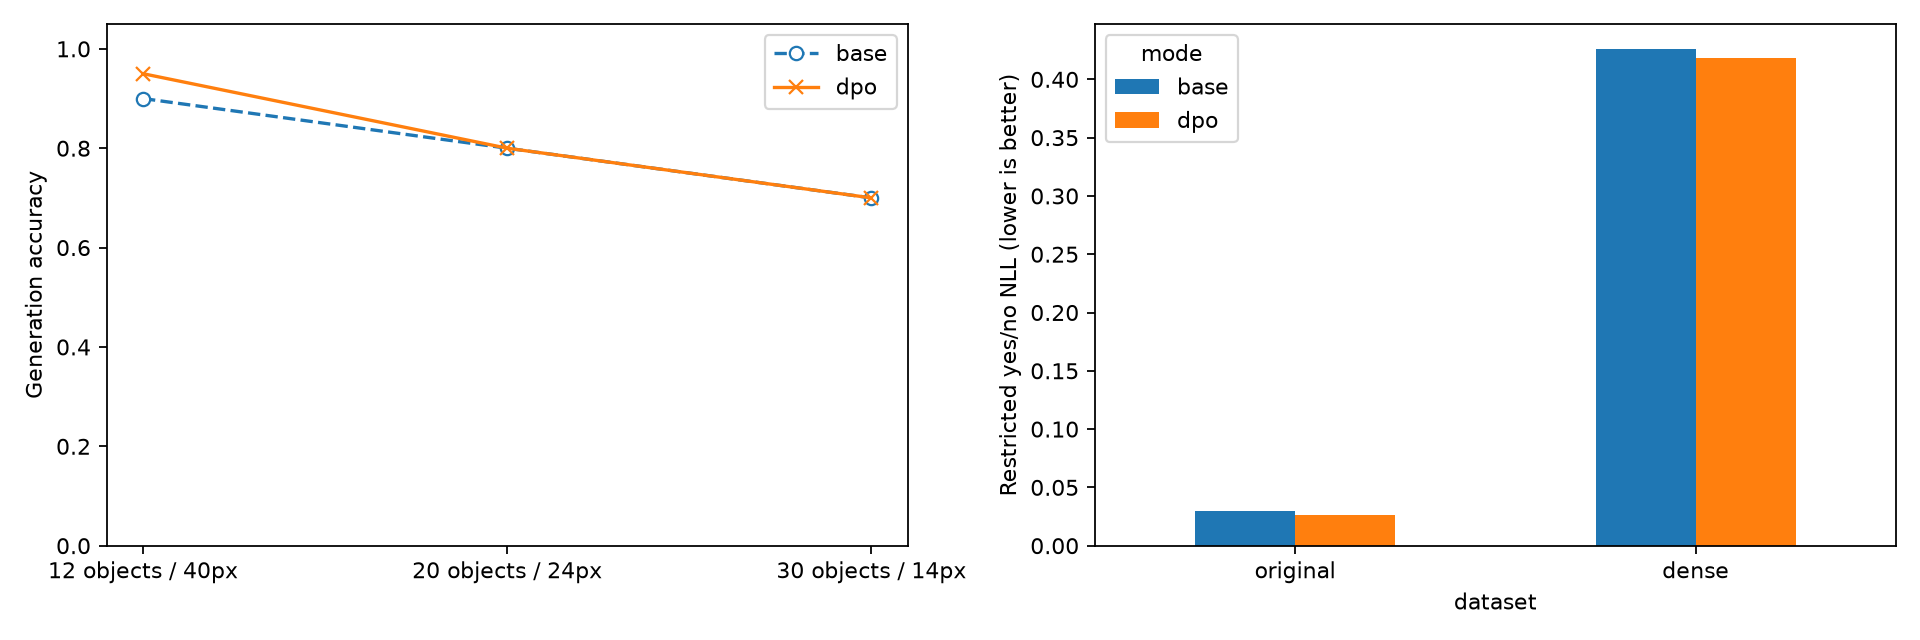

In [ ]:
LEVEL_RESULTS = pd.read_csv(OUT / 'visual_challenge_levels.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mode, style in [('base', 'o--'), ('dpo', 'x-')]:
    part = LEVEL_RESULTS[LEVEL_RESULTS['mode'] == mode].sort_values('category')
    axes[0].plot(range(1, 4), part['accuracy'], style, label=mode,
                 markerfacecolor='white' if mode == 'base' else None)
axes[0].set_xticks([1, 2, 3], ['12 objects / 40px', '20 objects / 24px', '30 objects / 14px'])
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel('Generation accuracy')
axes[0].legend()
VIS_DIAGNOSTICS.pivot(index='dataset', columns='mode', values='nll').reindex(['original', 'dense']).plot.bar(ax=axes[1])
axes[1].set_ylabel('Restricted yes/no NLL (lower is better)')
axes[1].tick_params(axis='x', labelrotation=0)
fig.tight_layout()
fig.savefig(OUT / 'visual_challenge_comparison.png', dpi=160)
plt.close(fig)
display(DisplayImage(filename=str(OUT / 'visual_challenge_comparison.png')))


### 補充測試結果分析

- 原始 30 題兩者仍皆為 1.0；正確答案平均機率由 0.9711 升至 0.9742，NLL 由 0.0298 降至 0.0265，說明答案不變時機率仍可能改變。
- 密集小物件測試由 48/60 升至 49/60（0.8000 → 0.8167）。淨增加 1 題，配對差值 95% 區間 [0.0000, 0.0500]，不足以證明穩定提升。
- 差異來自 CH019：base 將不存在的形狀答為 yes，DPO 改為 No；存在形狀的 30 題則兩者皆答對 19 題。
- 受限 yes/no 的 forced-choice accuracy 與自由生成不相同；本次 dense 的前者反而由 0.8167 降至 0.8000，故需將多種指標一起解讀。
- 完整設定、逐級結果、表格與後續改善方向整理於 README.md。


---
# 綜合結論

1. **LLM：** 低精度可節省記憶體，但品質與速度需實測；提示技巧在 dev 較好，不保證 test 也較好。
2. **VLM：** 嚴格答案與語意內容可能出現不同排名，需分開衡量辨識能力和格式遵循。
3. **DPO：** 文字目標平均分數小幅上升、通用平均分數小幅下降；原始視覺測試維持滿分，補充密集小物件測試為48/60→49/60。小樣本與天花板效果限制結論，不能將 adapter 更新等同能力必然提升。
4. **可重現性：** 保留 model revision、data manifest、環境、逐題輸出、adapter 與訓練 log。更改資料 / 超參數時另存實驗，完整快取不重跑模型。
